# Анализ и кластеризация сигналов сцинтилляционного детектора

## Описание задачи
Данные получены с осциллографа, подключенного к сцинтилляционному детектору. Каждая строка — это один зарегистрированный сигнал (500 временных отсчётов). Задача — кластеризовать сигналы на 3 группы: два типа частиц (гамма-кванты и нейтроны) и аномалии/шум.

**Основные этапы:**

1. Анализ структуры сигнала
2. Сравнение методов фильтрации
3. Выделение полезной области (отсечение шумовых хвостов)
4. Извлечение признаков
5. Анализ корреляций и отбор признаков
6. Поиск аномалий (выделение кластера 2)
7. Кластеризация нормальных сигналов (разделение на гамма-кванты и нейтроны)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import random
from datetime import datetime
from scipy.signal import butter, filtfilt, wiener
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

warnings.filterwarnings('ignore')

# Для воспроизводимости
SEED = 42
np.random.seed(SEED)


## EDA
### Загрузка данных и первичный анализ

In [2]:
# Data loading

dataset = pd.read_csv('datasets/Run200_Wave_0_1.txt', sep=' ', header=None, skipinitialspace=True)
dataset = dataset.drop([0, 1, 2, 3, 504], axis=1)
dataset.columns = list(range(500))
dataset.head()


,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
0,14820,14823,14824,14822,14818,14820,14824,14822,14820,14820,...,14828,14822,14815,14815,14817,14819,14820,14822,14820,14819
1,14820,14822,14820,14826,14824,14822,14820,14822,14823,14821,...,14828,14817,14824,14822,14824,14819,14820,14819,14822,14820
2,14820,14820,14822,14825,14820,14824,14824,14819,14823,14824,...,14820,14821,14820,14820,14818,14821,14823,14820,14820,14821
3,14828,14822,14818,14824,14824,14822,14820,14822,14824,14820,...,14824,14826,14822,14821,14820,14828,14820,14822,14823,14822
4,14823,14815,14823,14821,14827,14820,14823,14824,14816,14821,...,14820,14820,14823,14828,14824,14820,14824,14824,14822,14825


In [3]:
dataset.shape

(23479, 500)

Text(0, 0.5, 'bit ADC')

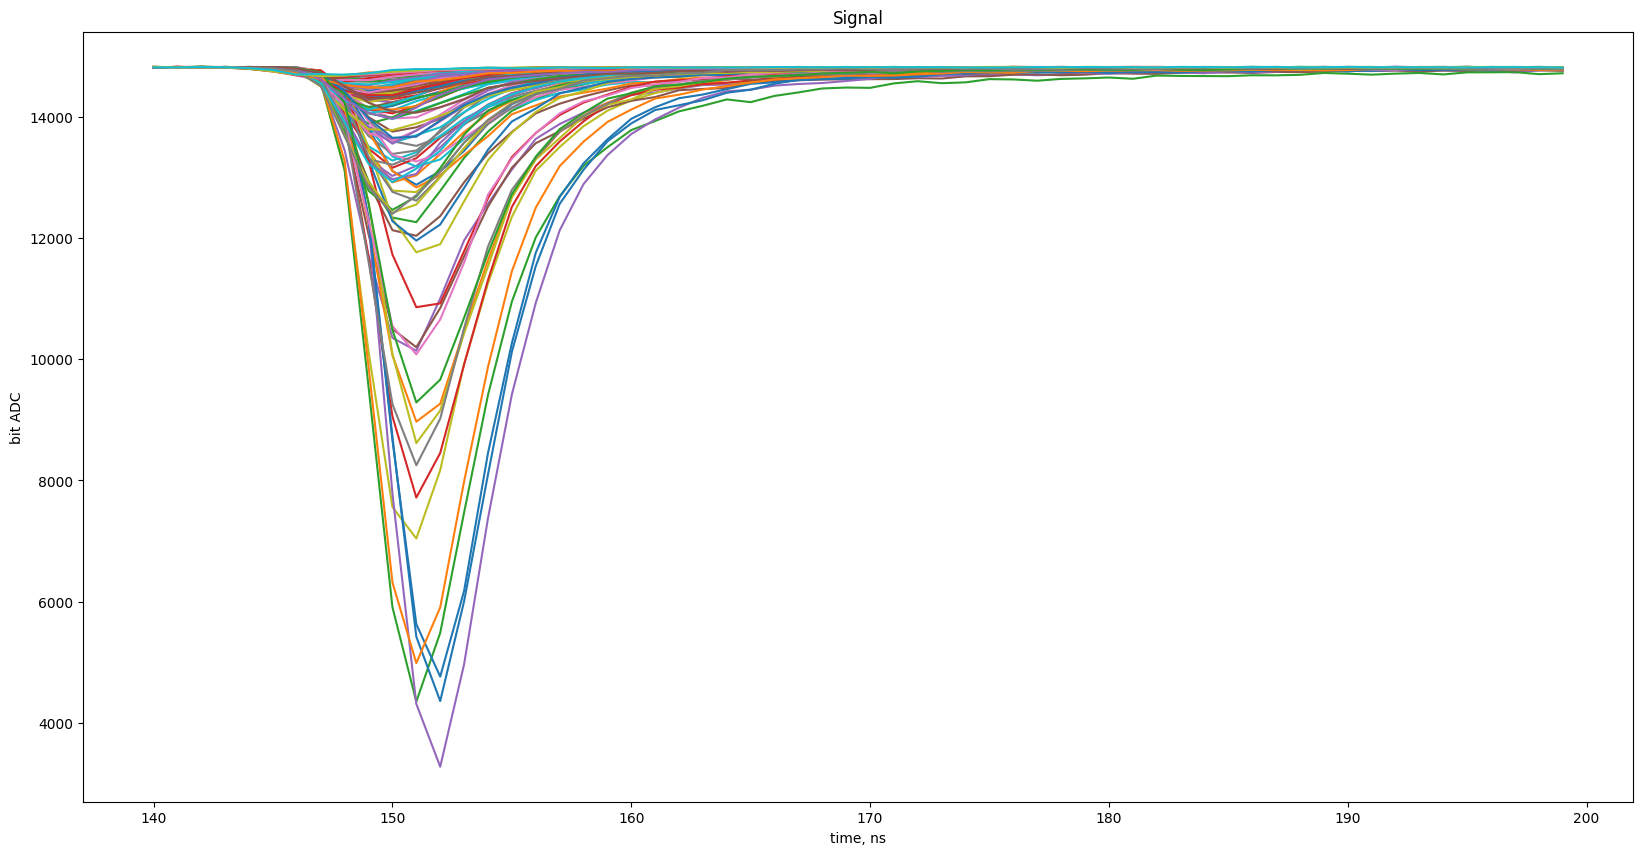

In [4]:
N=range(0,100)
ax = dataset.T[N][140:200].plot(title='Signal' ,legend=None,figsize=(20,10))
ax.set_xlabel("time, ns")
ax.set_ylabel("bit ADC")

Данные из дипломной работы содержат 2000 сигналов осциллометра с частотой дискретизации на сетке из 500 отсчетов.

На приведённых графиках видно, что у всех сигналов прослеживается общая структура: шум -> нарастание -> пик -> затухание -> шум. При этом длительность и форма затухания (зелёная область) заметно варьируется от сигнала к сигналу, что согласуется с утверждением из дипломной работы (раздел 2.1, стр. 13) о том, что именно период спада является информативным для разделения типов частиц.

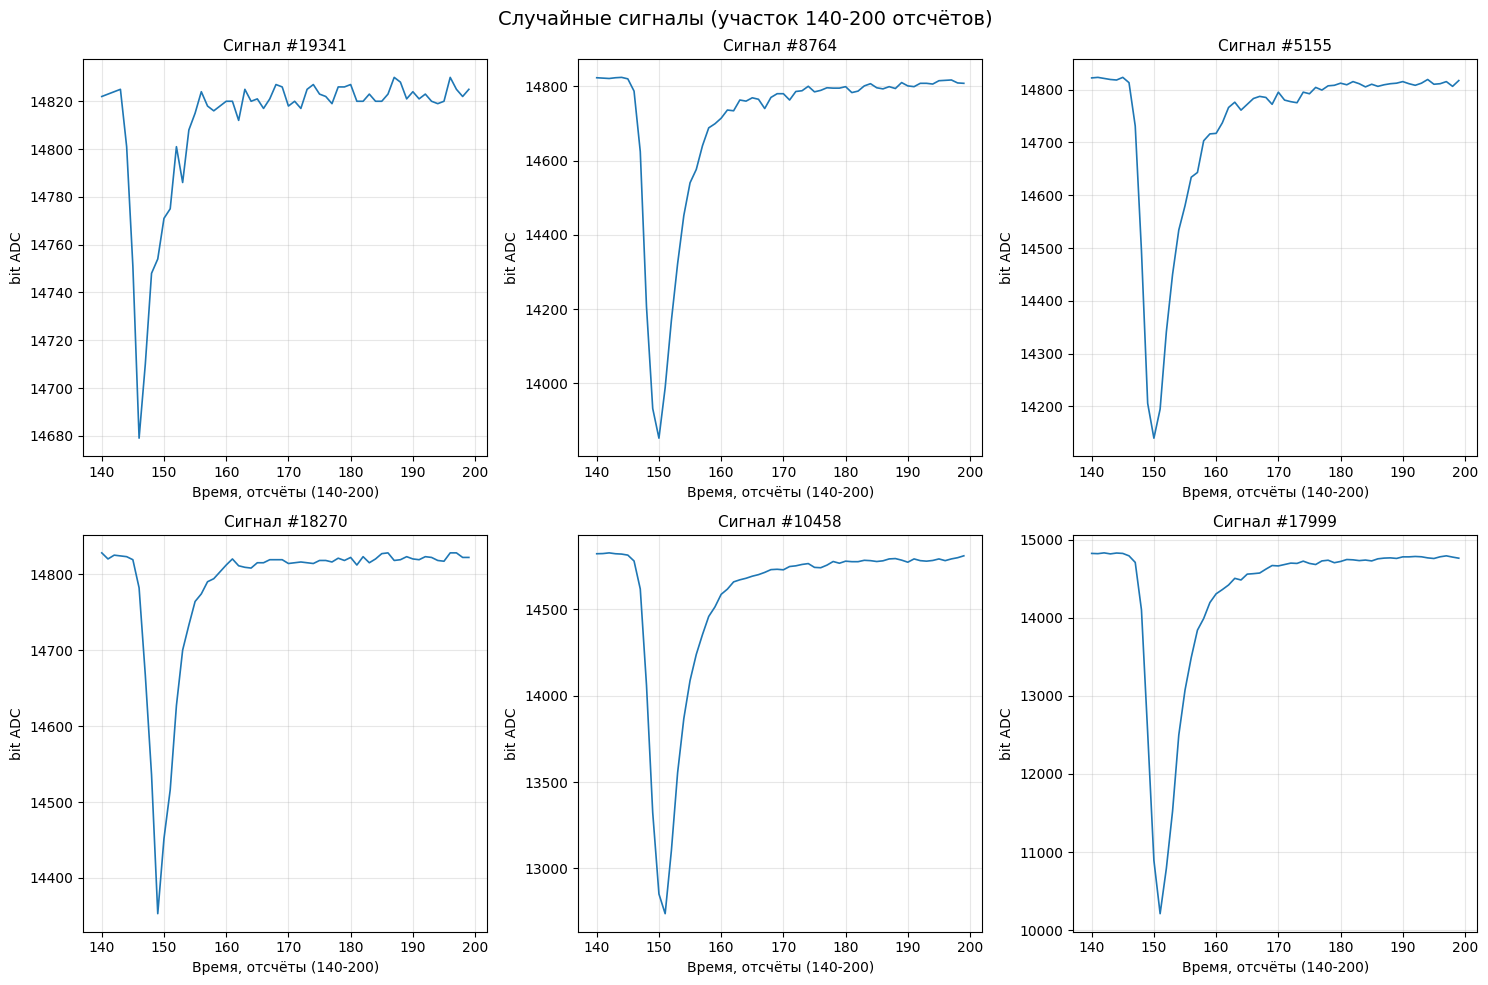

In [5]:
sample_indices = random.sample(range(len(dataset)), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    axes[i].plot(dataset.T[idx][140:200], linewidth=1.2)
    axes[i].set_title(f'Сигнал #{idx}', fontsize=11)
    axes[i].set_xlabel('Время, отсчёты (140-200)')
    axes[i].set_ylabel('bit ADC')
    axes[i].grid(True, alpha=0.3)
    

plt.suptitle('Случайные сигналы (участок 140-200 отсчётов)', fontsize=14)
plt.tight_layout()
plt.show()

На участке затухания сигналов присутствуют локальные экстремумы, что свидетельствует о наличии высокочастотного шума. Согласно физике сцинтилляционного детектора, форма затухания должна представлять собой плавную экспоненциальную кривую. Следовательно, наблюдаемые негладкости обусловлены следующими факторами: цифровым квантованием АЦП, электромагнитными наводками и шумами фотоэлектронного умножителя (ФЭУ).

Хотя последующее извлечение интегральных и статистических признаков частично компенсирует влияние шума, фильтрация остаётся необходимой. Её применение позволяет:

- более точно определять границы полезного сигнала за счёт снижения вероятности ложного срабатывания порога;
- повысить стабильность временных признаков (в частности, t50 и t10);
- улучшить качество экспоненциальной аппроксимации участка затухания.


### Предобработка сигналов.

Преобразование сырого сигнала в амплитудные значения переводит сигнал в положительную область, сохраняя всю информацию о форме (по формуле из дипломной работы: 2^14 - raw - 1560)

In [6]:
def convert_signal(raw_signal):
    return 2**14 - raw_signal - 1560

Для подавления высокочастотного шума рассматриваются три фильтра нижних частот:

- **Gaussian (σ=2)** — обеспечивает плавное сглаживание.  
  *Настройка:* увеличение σ усиливает сглаживание.

- **Wiener (mysize=5)** — адаптивный фильтр, подстраивается под локальные особенности сигнала.  
  *Настройка:* увеличение размера окна улучшает подавление шума, но может размывать детали.

- **Butterworth (cutoff=0.15, order=4)** — фильтр с гладкой частотной характеристикой.  
  *Настройка:* снижение cutoff усиливает сглаживание; увеличение order делает фильтр более резким, но может вызвать колебания.

In [7]:
def smooth_signal_gaussian(signal, sigma=2):
    return gaussian_filter1d(signal, sigma=sigma)

def smooth_signal_wiener(signal, mysize=5):
    return wiener(signal, mysize=mysize)

def smooth_signal_butterworth(signal, cutoff=0.15, order=4):
    b, a = butter(order, cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

def smooth_signal(signal, method='gaussian', **kwargs):
    if method == 'gaussian':
        sigma = kwargs.get('sigma', 2)
        return smooth_signal_gaussian(signal, sigma=sigma)
    elif method == 'wiener':
        mysize = kwargs.get('mysize', 5)
        return smooth_signal_wiener(signal, mysize=mysize)
    elif method == 'butter':
        cutoff = kwargs.get('cutoff', 0.15)
        order = kwargs.get('order', 4)
        return smooth_signal_butterworth(signal, cutoff=cutoff, order=order)
    else:
        raise ValueError(f"Unknown method: {method}. Choose from: 'gaussian', 'wiener', 'butter'")


Сравню результат выделения полезного сигнала (по методике из диплома, стр. 13-14) при использовании разных фильтров.

Порог отсечения вычисляется как `шум + 3σ`, где шум оценивается по первым 50 отсчётам. Сигналом считается область от пика до последнего превышения порога. Шумовые хвосты отбрасываются.

In [8]:
def extract_clean_signal(signal, left_tail_len=50, sigma_threshold=3):
    left_tail = signal[:left_tail_len]
    noise_mean = np.mean(left_tail)
    noise_std = np.std(left_tail)
    threshold = noise_mean + sigma_threshold * noise_std
    peak_idx = np.argmax(signal)
    
    start_idx = 0
    for i in range(peak_idx, -1, -1):
        if signal[i] < threshold:
            start_idx = i + 1
            break
    
    end_idx = len(signal) - 1
    for i in range(peak_idx, len(signal)):
        if signal[i] < threshold:
            end_idx = i - 1
            break
    
    clean_signal = signal[start_idx:end_idx+1]
    return clean_signal, noise_mean, noise_std, start_idx, end_idx, threshold

Полный пайплайн обработки одного сигнала:

In [9]:
def full_preprocessing_pipeline(raw_signal,
                                 smooth_method='gaussian',
                                 left_tail_len=50,
                                 sigma_threshold=3,
                                 **smooth_kwargs):
    converted = convert_signal(raw_signal)
    smoothed = smooth_signal(converted, method=smooth_method, **smooth_kwargs)
    clean, noise_mean, noise_std, start, end, threshold = extract_clean_signal(
        smoothed, left_tail_len=left_tail_len, sigma_threshold=sigma_threshold
    )
    
    metadata = {
        'noise_mean': noise_mean,
        'noise_std': noise_std,
        'threshold': threshold,
        'start_idx': start,
        'end_idx': end,
        'signal_length': len(clean),
        'peak_amplitude': np.max(clean) if len(clean) > 0 else 0,
        'smooth_method': smooth_method,
        **{f'smooth_{k}': v for k, v in smooth_kwargs.items()}
    }
    return clean, metadata


#### Сравнение методов фильтрации

Для визуальной оценки рассмотрены несколько случайных сигналов. С учётом небольшой выборки требуется подобрать мягкий фильтр, стабильно работающий для всех сигналов датасета.

**Критерии:** минимизация ложных срабатываний порога при выделении сигнала и сохранение формы затухания.

**Гиперпараметры:**
- Gaussian: σ=2 
- Wiener: mysize=5
- Butterworth: cutoff=0.2, order=3 



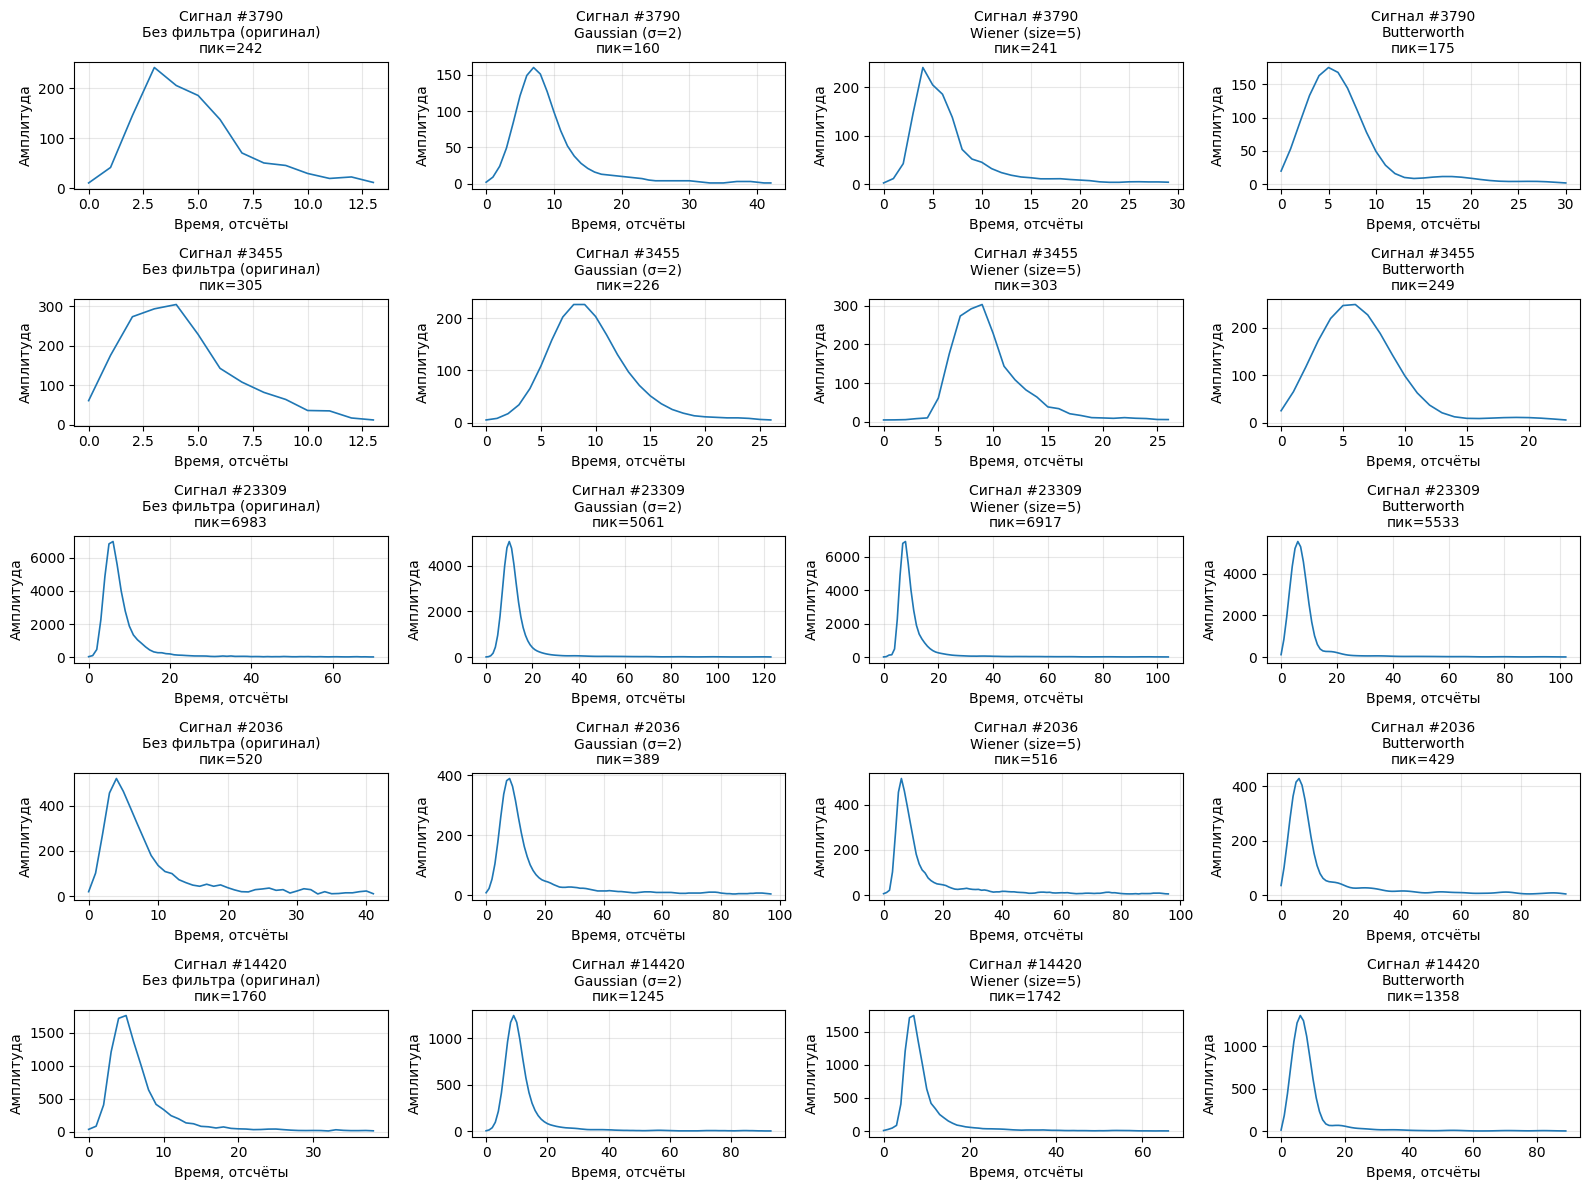

In [10]:
# Три разных сигнала
test_indices = random.sample(range(len(dataset)), 5)
signal_labels = [f'Сигнал #{idx}' for idx in test_indices]

# Методы фильтрации (добавляем 'none' - без фильтра)
methods = [
    ('none', {}, 'Без фильтра (оригинал)'),
    ('gaussian', {'sigma': 2}, 'Gaussian (σ=2)'),
    ('wiener', {'mysize': 5}, 'Wiener (size=5)'),
    ('butter', {'cutoff': 0.2, 'order': 3}, 'Butterworth')
]

# Создаём матрицу nx4 (n сигнала × 4 метода)
fig, axes = plt.subplots(len(test_indices), 4, figsize=(16, 12))

for row, (sig_idx, sig_title) in enumerate(zip(test_indices, signal_labels)):
    raw = dataset.iloc[sig_idx].values
    
    for col, (method, params, method_title) in enumerate(methods):
        if method == 'none':
            # Без фильтрации: только преобразование и выделение сигнала
            converted = convert_signal(raw)
            # extract_clean_signal возвращает 6 значений
            clean, noise_mean, noise_std, start, end, threshold = extract_clean_signal(converted)
            meta = {'peak_amplitude': np.max(clean) if len(clean) > 0 else 0}
        else:
            # С фильтрацией
            clean, meta = full_preprocessing_pipeline(raw, smooth_method=method, **params)
        
        axes[row, col].plot(clean, linewidth=1.2)
        axes[row, col].set_title(f'{sig_title}\n{method_title}\nпик={meta["peak_amplitude"]:.0f}', fontsize=10)
        axes[row, col].set_xlabel('Время, отсчёты')
        axes[row, col].set_ylabel('Амплитуда')
        axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Анализ результатов фильтрации


| Метод | Плюсы | Минусы |
|-------|-------|--------|
| **Без фильтра** | Сохраняет детали | Нестабильные границы из-за шума |
| **Gaussian (σ=2)** | Гладкий, стабильный | Уменьшает амплитуду на 20-25% |
| **Wiener (size=5)** | Сохраняет пик | Слабые колебания остаются |
| **Butterworth (cutoff=0.2)** | Сглаживает как Gaussian | Даёт артефакты на некоторых сигналах |

**Выбор фильтра для дальнейшей работы:**

Несмотря на незначительное уменьшение амплитуды, для дальнейшего анализа выбирается **фильтр Gaussian (σ=2)**, так как:
- фильтр обеспечивает стабильное и воспроизводимое выделение границ сигнала для всех сигналов датасета;
- фильтр даёт гладкую форму затухания без артефактов;
- снижение амплитуды не является критичным, так как для кластеризации важна форма сигнала, а не абсолютные значения амплитуды.


Функция для обработки всех сигналов датасета: преобразует амплитуду, фильтрует, выделяет полезную область и собирает метаданные (уровень шума, длина сигнала, амплитуда пика). Результатом является список очищенных сигналов и таблица с метаданными для последующего извлечения признаков.

In [11]:
def preprocess_all_signals(dataset,
                           smooth_method='gaussian',
                           left_tail_len=50,
                           sigma_threshold=3,
                           max_signals=None,
                           **smooth_kwargs):

    all_clean_signals = []
    all_metadata = []
    
    n_signals = len(dataset) if max_signals is None else min(max_signals, len(dataset))
    
    print(f"Начинаем обработку {n_signals} сигналов...")
    print(f"Метод сглаживания: {smooth_method}")
    
    for idx in range(n_signals):
        raw = dataset.iloc[idx].values
        
        if smooth_method == 'none':
            # Без фильтрации
            converted = convert_signal(raw)
            clean, noise_mean, noise_std, start, end, threshold = extract_clean_signal(
                converted, left_tail_len=left_tail_len, sigma_threshold=sigma_threshold
            )
            metadata = {
                'noise_mean': noise_mean,
                'noise_std': noise_std,
                'threshold': threshold,
                'start_idx': start,
                'end_idx': end,
                'signal_length': len(clean),
                'peak_amplitude': np.max(clean) if len(clean) > 0 else 0,
                'smooth_method': 'none'
            }
        else:
            # С фильтрацией
            clean, metadata = full_preprocessing_pipeline(
                raw,
                smooth_method=smooth_method,
                left_tail_len=left_tail_len,
                sigma_threshold=sigma_threshold,
                **smooth_kwargs
            )
        
        if len(clean) > 10:
            metadata['original_idx'] = idx
            all_clean_signals.append(clean)
            all_metadata.append(metadata)
        
        if (idx + 1) % 500 == 0:
            print(f"  \rОбработано {idx + 1} / {n_signals} сигналов...", flush=True, end='')
    print()  # перевод строки после завершения

    metadata_df = pd.DataFrame(all_metadata)

    
    return all_clean_signals, metadata_df

### Извлечение признаков

На основе методов параметризации, описанных в дипломной работе, а также анализа структуры сигналов формируется набор признаков, характеризующих в первую очередь **форму затухания** — ключевую область для различения типов частиц.

| Признак | Краткое описание | Источник / Обоснование |
|---------|------------------|------------------------|
| `psd` | (long - short)/long — доля энергии в хвосте сигнала | Раздел 2.2.3 |
| `t50`, `t30`, `t10` | Время спада до 50/30/10% амплитуды пика | Раздел 2.2.2 |
| `decay_time_constant` | Постоянная τ экспоненциальной аппроксимации участка затухания | Раздел 2.2.2 |
| `amplitude` | Максимальная амплитуда сигнала | Раздел 2.2.4 |
| `total_integral` | Полная площадь под сигналом | Раздел 2.2.4 |
| `tail_early_ratio`, `tail_mid_ratio`, `tail_late_ratio` | Доля энергии в различных участках хвоста | Развитие PSD |
| `mid_to_early`, `late_to_mid` | Отношение энергии между частями хвоста | Развитие PSD |
| `fwhm` | Ширина сигнала на половине максимума | Дополнительный |
| `signal_length` | Длина выделенного полезного сигнала | Характеристика продолжительности затухания |
| `snr` | Отношение сигнал/шум (только для сырых данных) | Показатель качества сигнала |

> **Примечание:** `snr` имеет смысл только для нефильтрованных данных. Для сигналов, обработанных фильтром Гаусса, шум подавлен, поэтому SNR исключается из набора признаков.


In [12]:
def extract_selected_features(clean_signals, original_amplitudes, metadata=None):
    # Если список не передан — используем признаки, описывающие затухание
    feature_list = [
        # Амплитудные и интегральные
        'amplitude', 'total_integral', 'psd',
        # Распределение энергии в хвосте
        'tail_early_ratio', 'tail_mid_ratio', 'tail_late_ratio',
        'mid_to_early', 'late_to_mid',
        # Временные характеристики затухания
        't50', 't30', 't10', 'fwhm', 'decay_time_constant',
        # Продолжительность
        'signal_length',
        # Качество (только для сырых данных)
        'snr'
    ]
    
    all_features = []
    
    for idx, (sig, amp) in enumerate(zip(clean_signals, original_amplitudes)):
        sig_len = len(sig)
        peak_idx = np.argmax(sig)
        total_integral = np.sum(sig)
        half_max = amp / 2
        
        f = {}
        
        for feature_name in feature_list:
            
            # === Амплитудные и интегральные ===
            if feature_name == 'amplitude':
                f['amplitude'] = amp
                
            elif feature_name == 'total_integral':
                f['total_integral'] = total_integral
                
            elif feature_name == 'psd':
                short_window = min(20, sig_len - peak_idx)
                short_integral = np.sum(sig[peak_idx:peak_idx + short_window]) if short_window > 0 else 0
                f['psd'] = (total_integral - short_integral) / total_integral if total_integral > 0 else 0
            
            # === Распределение энергии в хвосте ===
            elif feature_name == 'tail_early_ratio':
                tail_start = min(peak_idx + 10, sig_len)
                tail_end = min(peak_idx + 50, sig_len)
                tail_integral = np.sum(sig[tail_start:tail_end]) if tail_start < sig_len else 0
                f['tail_early_ratio'] = tail_integral / total_integral if total_integral > 0 else 0
                
            elif feature_name == 'tail_mid_ratio':
                tail_start = min(peak_idx + 50, sig_len)
                tail_end = min(peak_idx + 100, sig_len)
                tail_integral = np.sum(sig[tail_start:tail_end]) if tail_start < sig_len else 0
                f['tail_mid_ratio'] = tail_integral / total_integral if total_integral > 0 else 0
                
            elif feature_name == 'tail_late_ratio':
                tail_start = int(sig_len * 0.7)
                tail_integral = np.sum(sig[tail_start:]) if tail_start < sig_len else 0
                f['tail_late_ratio'] = tail_integral / total_integral if total_integral > 0 else 0
                
            elif feature_name == 'mid_to_early':
                tail_early_start = min(peak_idx + 10, sig_len)
                tail_early_end = min(peak_idx + 50, sig_len)
                tail_early = np.sum(sig[tail_early_start:tail_early_end]) if tail_early_start < sig_len else 0
                
                tail_mid_start = min(peak_idx + 50, sig_len)
                tail_mid_end = min(peak_idx + 100, sig_len)
                tail_mid = np.sum(sig[tail_mid_start:tail_mid_end]) if tail_mid_start < sig_len else 0
                
                f['mid_to_early'] = tail_mid / (tail_early + 1e-6)
                
            elif feature_name == 'late_to_mid':
                tail_mid_start = min(peak_idx + 50, sig_len)
                tail_mid_end = min(peak_idx + 100, sig_len)
                tail_mid = np.sum(sig[tail_mid_start:tail_mid_end]) if tail_mid_start < sig_len else 0
                
                tail_late_start = int(sig_len * 0.7)
                tail_late = np.sum(sig[tail_late_start:]) if tail_late_start < sig_len else 0
                
                f['late_to_mid'] = tail_late / (tail_mid + 1e-6)
            
            # === Временные характеристики затухания ===
            elif feature_name == 't50':
                t50 = 0
                for i in range(peak_idx, sig_len):
                    if sig[i] < half_max:
                        t50 = i - peak_idx
                        break
                f['t50'] = int(round(t50)) 
                
            elif feature_name == 't30':
                third_max = amp * 0.3
                t30 = 0
                for i in range(peak_idx, sig_len):
                    if sig[i] < third_max:
                        t30 = i - peak_idx
                        break
                f['t30'] = int(round(t30)) 
                
            elif feature_name == 't10':
                tenth_max = amp * 0.1
                t10 = 0
                for i in range(peak_idx, sig_len):
                    if sig[i] < tenth_max:
                        t10 = i - peak_idx
                        break
                f['t10'] = int(round(t10)) 
                
            elif feature_name == 'fwhm':
                left_idx = peak_idx
                right_idx = peak_idx
                for i in range(peak_idx, -1, -1):
                    if sig[i] < half_max:
                        left_idx = i
                        break
                for i in range(peak_idx, sig_len):
                    if sig[i] < half_max:
                        right_idx = i
                        break
                fwhm = right_idx - left_idx
                f['fwhm'] = int(round(fwhm)) 
            
            elif feature_name == 'decay_time_constant':
                def exp_decay(t, a, tau, c):
                    return a * np.exp(-t / tau) + c
                try:
                    decay_region = sig[peak_idx:min(peak_idx + 100, sig_len)]
                    if len(decay_region) > 10:
                        t_decay = np.arange(len(decay_region))
                        popt, _ = curve_fit(exp_decay, t_decay, decay_region, p0=[amp, 20, 0], maxfev=1000)
                        f['decay_time_constant'] = popt[1]
                    else:
                        f['decay_time_constant'] = 0
                except:
                    f['decay_time_constant'] = 0
            
            # === Продолжительность ===
            elif feature_name == 'signal_length':
                f['signal_length'] = sig_len
            
            # === Качество сигнала ===
            elif feature_name == 'snr':
                if metadata is not None and idx < len(metadata):
                    noise_std = metadata.iloc[idx].get('noise_std', np.std(sig[:50]))
                else:
                    noise_std = np.std(sig[:50])
                f['snr'] = amp / (noise_std + 1e-6)
        
        all_features.append(f)
    
    return pd.DataFrame(all_features)

In [13]:
MAX_SIGNALS = None
SMOOTH_METHOD = 'gaussian'
SMOOTH_PARAMS = {'sigma': 2}

print("Обработка сигналов с фильтром Gaussian (σ=2)")
print(f"Сигналов: {MAX_SIGNALS}")

# Предобработка
clean_signals, metadata = preprocess_all_signals(
    dataset,
    smooth_method=SMOOTH_METHOD,
    max_signals=MAX_SIGNALS,
    verbose=True,
    **SMOOTH_PARAMS
)

# Извлечение признаков
original_amps = metadata['peak_amplitude'].values
df_gaussian = extract_selected_features(clean_signals, original_amps, metadata=metadata)

print(f"\nГотово: {df_gaussian.shape[0]} сигналов, {df_gaussian.shape[1]} признаков")
df_gaussian.columns

Обработка сигналов с фильтром Gaussian (σ=2)
Сигналов: None
Начинаем обработку 23479 сигналов...
Метод сглаживания: gaussian
Обработано 23000 / 23479 сигналов...                                                                                        

Готово: 23479 сигналов, 15 признаков


Index(['amplitude', 'total_integral', 'psd', 'tail_early_ratio',
       'tail_mid_ratio', 'tail_late_ratio', 'mid_to_early', 'late_to_mid',
       't50', 't30', 't10', 'fwhm', 'decay_time_constant', 'signal_length',
       'snr'],
      dtype='object')

#### Анализ и выбор признаков

Проанализирую распределения признаков.

In [14]:
df_gaussian.describe().round(4)

,amplitude,total_integral,psd,tail_early_ratio,tail_mid_ratio,tail_late_ratio,mid_to_early,late_to_mid,t50,t30,t10,fwhm,decay_time_constant,signal_length,snr
count,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000,2.347900e+04,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000,2.347900e+04
mean,1331.2701,12897.7839,0.3920,0.1288,0.0221,0.0314,0.1484,2.876549e+07,4.7795,6.7789,12.5456,8.6337,5.1006,102.4735,2.515374e+06
std,1729.7371,16059.0818,0.0431,0.0581,0.0235,0.0206,0.1367,4.355274e+07,0.5908,0.8694,3.0436,0.6364,0.7077,71.5991,9.735393e+07
min,81.0000,597.0000,0.2388,0.0000,0.0000,0.0024,0.0000,2.064000e-01,3.0000,5.0000,8.0000,7.0000,0.0000,15.0000,7.223060e+01
25%,224.0000,2262.5000,0.3605,0.0773,0.0000,0.0152,0.0000,5.354000e-01,4.0000,6.0000,10.0000,8.0000,4.5730,46.0000,3.411435e+02
50%,590.0000,5963.0000,0.3954,0.1250,0.0140,0.0267,0.1552,1.117100e+00,5.0000,7.0000,12.0000,9.0000,5.0421,82.0000,9.046821e+02
75%,1684.5000,16968.5000,0.4236,0.1784,0.0441,0.0431,0.2779,6.100000e+07,5.0000,7.0000,14.0000,9.0000,5.5352,140.0000,2.588675e+03
max,12293.0000,112936.0000,0.5252,0.3281,0.1330,0.1972,0.9245,3.310000e+08,8.0000,12.0000,32.0000,12.0000,22.7877,500.0000,7.296000e+09


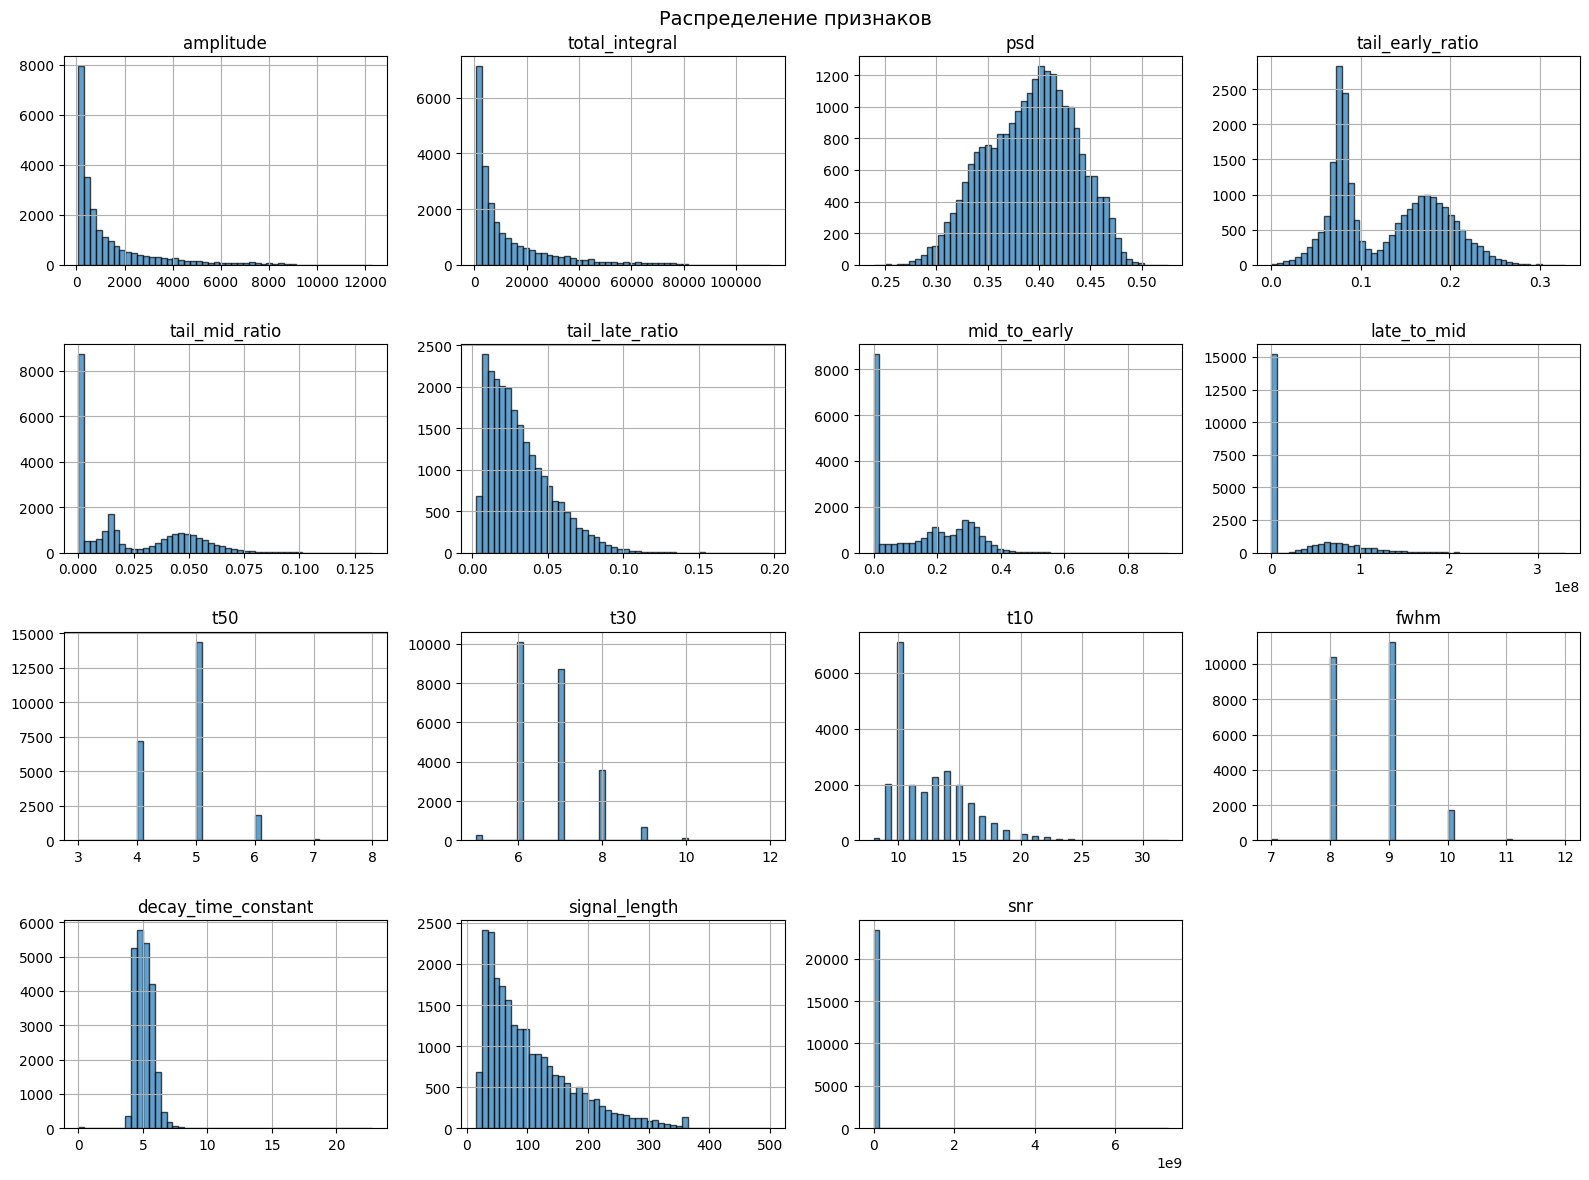

In [15]:
df_gaussian.hist(bins=50, figsize=(16, 12), edgecolor='black', alpha=0.7)
plt.suptitle('Распределение признаков', fontsize=14)
plt.tight_layout()
plt.show()

#### Анализ распределений признаков

Признаки будут использоваться в следующих целях.
1. Отделить аномальные сигналы от нормальных;
2. В группе нормальных сигналов выделить два типа сигналов, предположительно соответствующих гамма-квантам и нейтронам.

**Сводная таблица признаков**

| Группа | Признаки | Описание распределения | Роль в задаче | Решение |
|--------|----------|------------------------|---------------|---------|
| **Амплитудные** | `amplitude`, `total_integral` | Сильно скошены вправо | Аномалии — аномально низкая или высокая амплитуда. Нормальные сигналы — плавное убывание. | Проверить корреляцию, оставить один |
| **Энергия хвоста** | `tail_mid_ratio`, `tail_late_ratio`, `late_to_mid`, `mid_to_early` | Бимодальное: резкий пик в нуле + правый тяжёлый хвост (возможно, с несколькими локальными максимумами) | Маленькие положительные значения - гамма (короткий хвост). Большие значения - нейтроны (длинный хвост). | Проверить корреляцию, возможно оставить только некоторые |
| **Ранний хвост** | `tail_early_ratio` | Бимодальное (два различимых пика) | Хорошо отражает различия в ранней стадии затухания. Возможно, один из наиболее информативных. | **Критичен** — оставить |
| **Форма импульса** | `psd` | Смещённое нормальное, широкое, бимодальность слабо выражена | Самостоятельно типы сигналов не разделяет. Полезен в комбинации с признаками хвоста для уточнения границ между кластерами. | Проверить корреляцию, возможно оставить |
| **Времена спада** | `t50`, `t30`, `t10`, `fwhm` | Дискретные распределения | Скорость затухания на разных уровнях. Более низкие пороги (`t10`) чувствительнее к хвосту. | Проверить корреляцию, возможно, сократить до `t50` и `t10` |
| **Затухание** | `decay_time_constant` | Близко к нормальному с выраженным пиком | Отражает скорость экспоненциального затухания. Крайние значения - редкие или аномальные сигналы. | Оставить как вспомогательный |
| **Длительность** | `signal_length` | Скошено вправо | Продолжительность полезного сигнала. Короткие - быстрое затухание (гамма), длинные - медленное (нейтроны). | Оставить как вспомогательный |
| **Качество** | `snr` | Один выраженный пик | После фильтрации шум подавлен, признак теряет информативность. | **Удалить** для Gaussian |

#### Итоговый вывод

Для ряда признаков наблюдается разделение на два режима, что подтверждает гипотезу о двух типах сигналов.

| Категория | Признаки |
|-----------|----------|
| Потенциально наиболее информативные | `tail_early_ratio`, `tail_mid_ratio`, `tail_late_ratio`, `late_to_mid`, `decay_time_constant` |
| Вспомогательные | `amplitude`, `t50`, `t10`, `signal_length`, `psd` |
| Исключаемые | `snr` (для фильтрованных данных); дублирующиеся пары после корреляционного анализа (`total_integral`, `mid_to_early`, `t30`, `fwhm` и др.) |

> После корреляционного анализа дублирующие признаки будут удалены, и финальный набор будет сокращён до минимально достаточного.

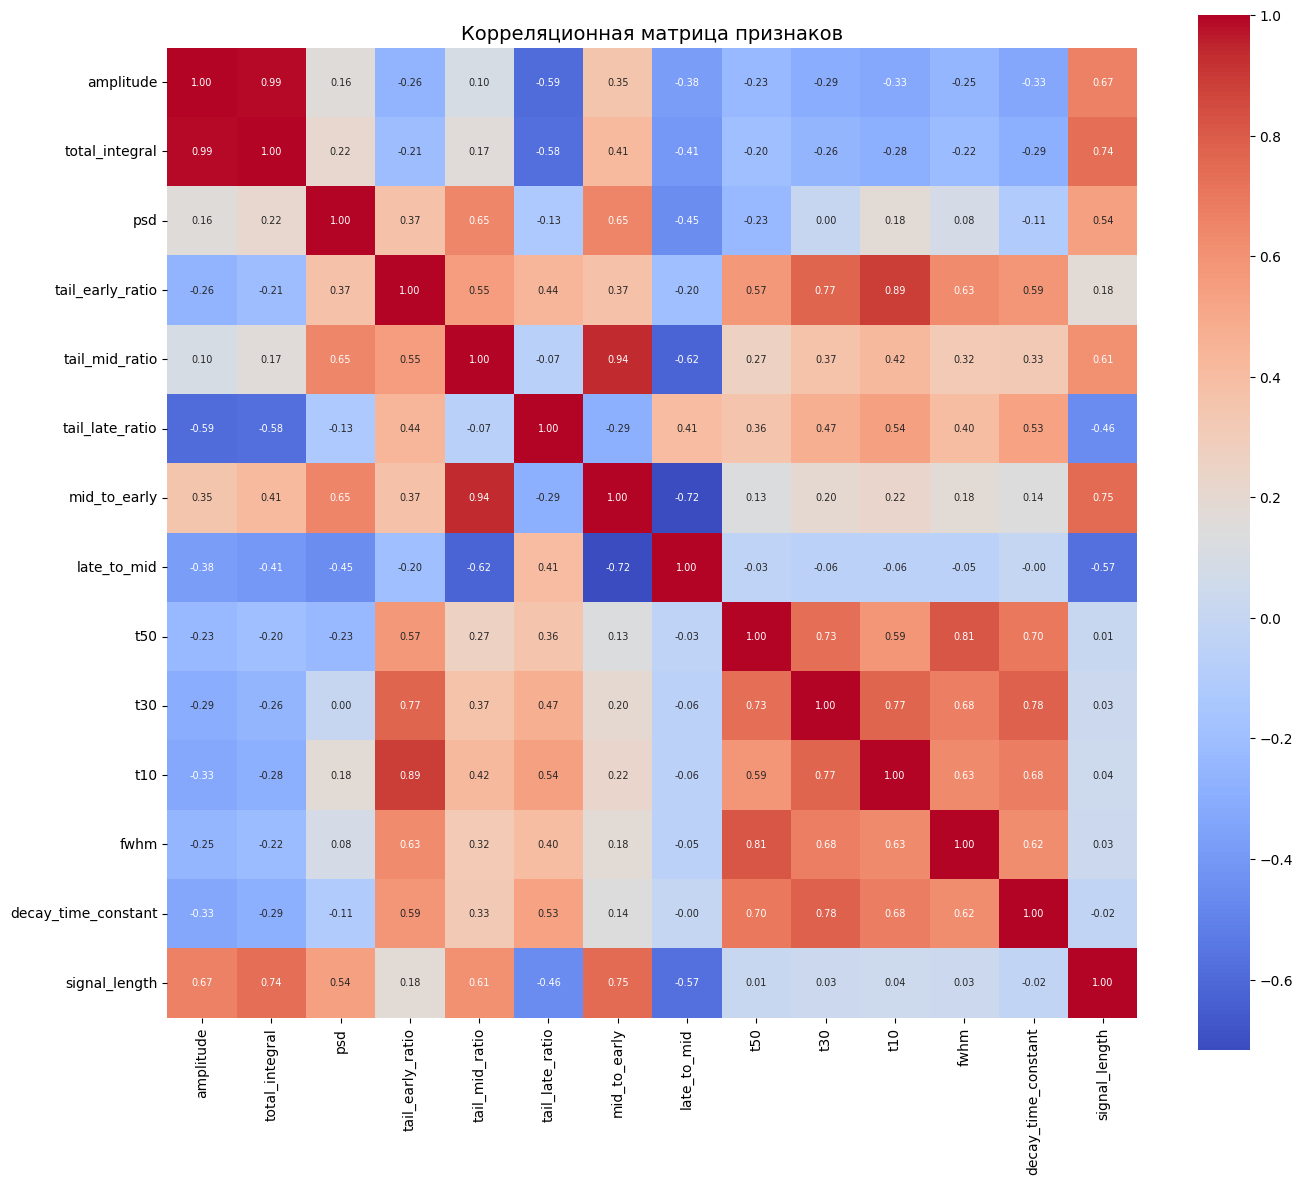


=== СИЛЬНЫЕ КОРРЕЛЯЦИИ (|r| > 0.85) ===
amplitude            - total_integral      : 0.993
tail_early_ratio     - t10                 : 0.889
tail_mid_ratio       - mid_to_early        : 0.937

Найдено сильных корреляций: 3


In [16]:
# Выбираем числовые признаки (исключаем служебные колонки)
feature_cols = [col for col in df_gaussian.columns if col not in ['method', 'signal_length_original', 'snr']]

# Корреляционная матрица
corr_matrix = df_gaussian[feature_cols].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            square=True, annot_kws={'size': 7})
plt.title('Корреляционная матрица признаков', fontsize=14)
plt.tight_layout()
plt.show()

# Поиск сильных корреляций
print("\n=== СИЛЬНЫЕ КОРРЕЛЯЦИИ (|r| > 0.85) ===")
strong_corr = []
for i in range(len(feature_cols)):
    for j in range(i+1, len(feature_cols)):
        corr_val = corr_matrix.iloc[i, j]
        if abs(corr_val) > 0.85:
            strong_corr.append((feature_cols[i], feature_cols[j], corr_val))
            print(f"{feature_cols[i]:<20} - {feature_cols[j]:<20}: {corr_val:.3f}")

print(f"\nНайдено сильных корреляций: {len(strong_corr)}")

### Анализ корреляций и выбор признаков

Корреляционный анализ выявил три пары признаков с |r| > 0.85:

| Пара | Коэффициент | Удалён | Причина выбора |
|------|-------------|--------|----------------|
| `amplitude` - `total_integral` | 0.993 | `total_integral` | `amplitude` имеет более прямой физический смысл (пиковая амплитуда) и проще интерпретируется |
| `tail_early_ratio` - `t10` | 0.897 | `t10` | `tail_early_ratio` имеет более плавное распределение и лучше отражает различия в ранней стадии затухания, тогда как `t10` дискретен и менее информативен |
| `tail_mid_ratio` - `mid_to_early` | 0.936 | `mid_to_early` | `tail_mid_ratio` (доля энергии в среднем хвосте) более наглядна, чем отношение двух интегралов |

Высококоррелированные признаки не оказывают существенного влияния на качество кластеризации, однако их удаление упрощает модель и повышает устойчивость анализа.

**Набор после анализа корреляции — 11 признаков:** `amplitude`, `psd`, `tail_early_ratio`, `tail_mid_ratio`, `tail_late_ratio`, `late_to_mid`, `t50`, `t30`, `fwhm`, `decay_time_constant`, `signal_length`. Признаки не дублируют друг друга и полностью характеризуют форму затухания сигнала.

In [17]:
final_features = [
    'amplitude',  
    'psd',       
    'tail_early_ratio',  
    'tail_mid_ratio',   
    'tail_late_ratio',   
    'late_to_mid',      
    't50',                
    't30',                
    'decay_time_constant',
    'fwhm',                
    'signal_length'        
]

# Создаём датафрейм
final_df = df_gaussian[final_features].copy()
final_df.describe().round(4)

,amplitude,psd,tail_early_ratio,tail_mid_ratio,tail_late_ratio,late_to_mid,t50,t30,decay_time_constant,fwhm,signal_length
count,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000,2.347900e+04,23479.0000,23479.0000,23479.0000,23479.0000,23479.0000
mean,1331.2701,0.3920,0.1288,0.0221,0.0314,2.876549e+07,4.7795,6.7789,5.1006,8.6337,102.4735
std,1729.7371,0.0431,0.0581,0.0235,0.0206,4.355274e+07,0.5908,0.8694,0.7077,0.6364,71.5991
min,81.0000,0.2388,0.0000,0.0000,0.0024,2.064000e-01,3.0000,5.0000,0.0000,7.0000,15.0000
25%,224.0000,0.3605,0.0773,0.0000,0.0152,5.354000e-01,4.0000,6.0000,4.5730,8.0000,46.0000
50%,590.0000,0.3954,0.1250,0.0140,0.0267,1.117100e+00,5.0000,7.0000,5.0421,9.0000,82.0000
75%,1684.5000,0.4236,0.1784,0.0441,0.0431,6.100000e+07,5.0000,7.0000,5.5352,9.0000,140.0000
max,12293.0000,0.5252,0.3281,0.1330,0.1972,3.310000e+08,8.0000,12.0000,22.7877,12.0000,500.0000


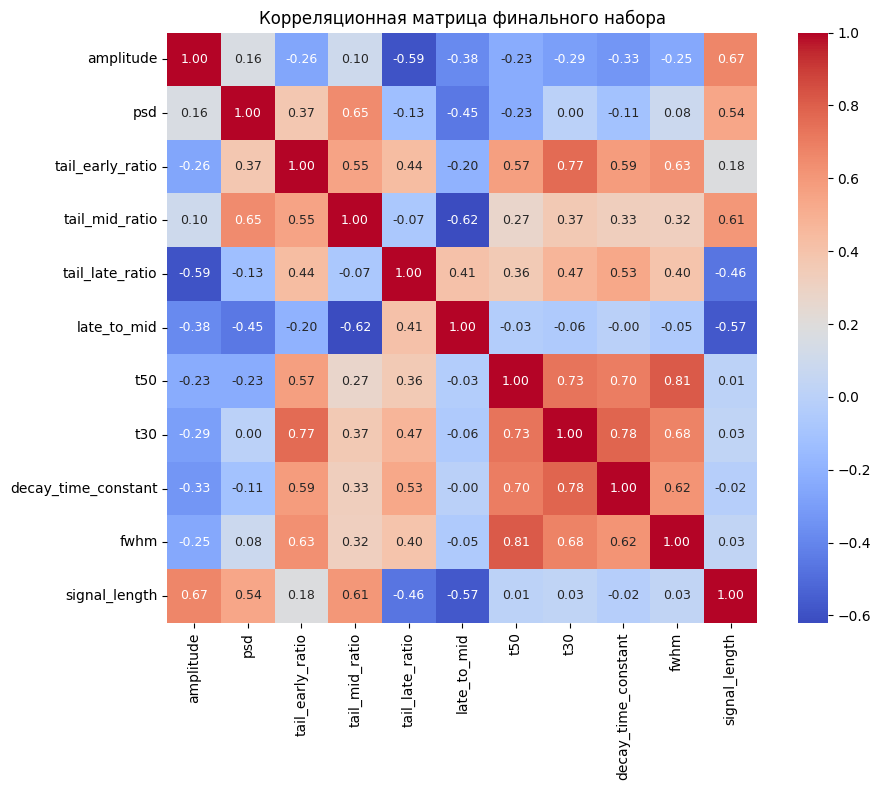

In [18]:
# Проверка корреляций
corr_final = final_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_final, annot=True, fmt='.2f', cmap='coolwarm', 
            square=True, annot_kws={'size': 9})
plt.title('Корреляционная матрица финального набора', fontsize=12)
plt.tight_layout()
plt.show()

Признаки имеют разный масштаб. Для корректной работы методов кластеризации, основанных на расстояниях (KMeans, GMM, DBSCAN, Agglomerative), необходимо привести все признаки к единому масштабу, использую StandardScaler. Для подбора гиперпараметров использую выборку из 2000 сигналов.

In [19]:
X = df_gaussian[final_features].copy()

# Масштабирование (обязательно для OneClassSVM и IsolationForest)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("="*70)
print("ПОДГОТОВКА ДАННЫХ ДЛЯ ПОИСКА АНОМАЛИЙ")
print("="*70)
print(f"Количество сигналов: {X_scaled.shape[0]}")
print(f"Количество признаков: {X_scaled.shape[1]}")
print(f"Признаки масштабированы (среднее=0, дисперсия=1)")

ПОДГОТОВКА ДАННЫХ ДЛЯ ПОИСКА АНОМАЛИЙ
Количество сигналов: 23479
Количество признаков: 11
Признаки масштабированы (среднее=0, дисперсия=1)


#### Визуализация данных с помощью PCA

Для оценки структуры данных построим PCA-проекцию. Это позволит визуально оценить, насколько сигналы разделимы на группы, и выявить возможные аномалии. Далее попробую сделать разделение кластеров более очевидным за счёт подбора оптимального набора признаков.

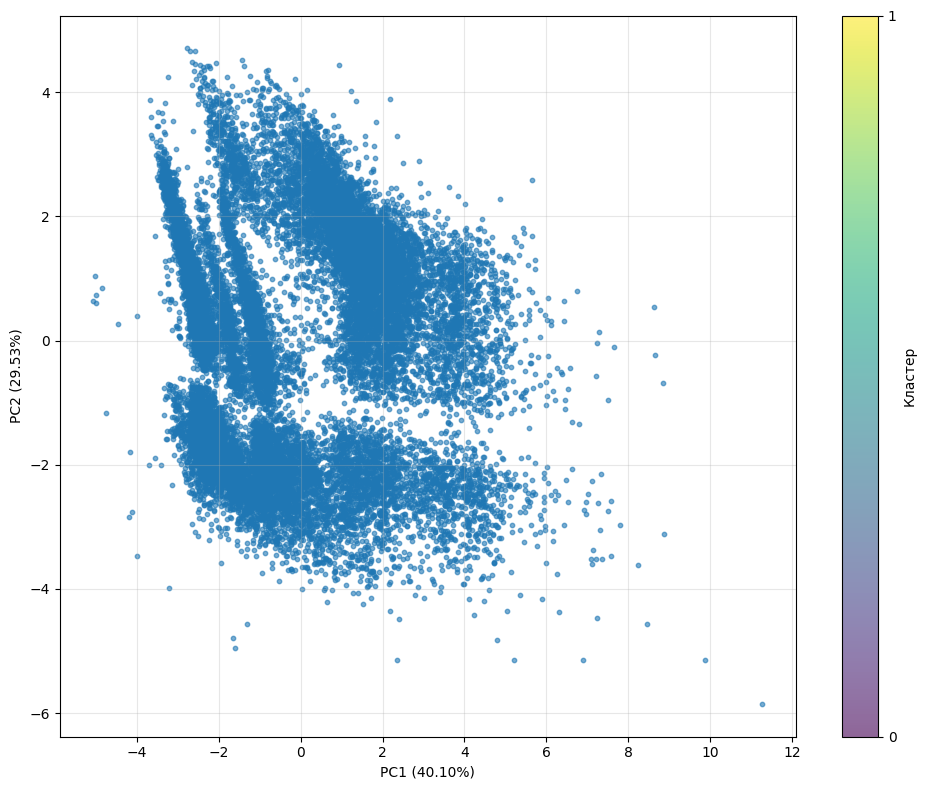

In [20]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                      cmap='viridis', s=10, alpha=0.6)
plt.colorbar(scatter, ticks=[0, 1, 2], label='Кластер')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Разделение на два кластера не очевидно. Попробую удалить некоторые признаки.

In [21]:
# final_features = [
#     'amplitude', 
#     'psd', 
#     'tail_early_ratio', 
#     'tail_mid_ratio', 
#     'tail_late_ratio', 
#     'late_to_mid', 
#    # 't50', 
#  #   't30', 
#     'decay_time_constant', 
#    # 'fwhm', 
#     'signal_length'
#    ]

# X_scaled = StandardScaler().fit_transform(X[final_features])


# pca = PCA(n_components=2, random_state=SEED)
# X_pca = pca.fit_transform(X_scaled)

# plt.figure(figsize=(8, 6))
# plt.scatter(X_pca[:, 0], X_pca[:, 1], c='steelblue', s=8, alpha=0.5)
# plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
# plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
# plt.title(f'PCA проекция')
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

**Вывод по отбору признаков**

Дискретные признаки (`t50`, `t30`, `fwhm`) искажают PCA-проекцию, создавая ступенчатую структуру. Однако для Isolation Forest и Agglomerative Clustering эти искажения не критичны. Эксперимент показал, что удаление дискретных признаков ухудшает результат, поэтому в финальное решение включены все признаки.

### Итоговый вывод по EDA

В результате разведочного анализа установлено следующее.

1. **Структура сигналов** едина для всех измерений: шум → нарастание → пик → затухание → шум. Именно форма затухания варьируется от сигнала к сигналу и является ключевой для разделения типов частиц.

2. **Присутствует высокочастотный шум**, не связанный с физикой процесса. Фильтр **Gaussian (σ=2)** показал лучший баланс между сглаживанием и сохранением формы затухания без артефактов.

3. **Сформирован набор из 11 признаков**, характеризующих форму затухания. Благодаря корреляционному анализу удалены три дублирующих признака (`total_integral`, `t10`, `mid_to_early`), что упростило модель без потери информации.

4. Данные подготовлены для следующих этапов: **поиск аномалий** и **кластеризация** на три группы (гамма-кванты, нейтроны, шум/аномалии).

## Поиск аномалий

Аномальные сигналы ожидаются редкими (не более 5–10% от общего числа). Для их выделения сравниваются три метода: 
- **Isolation Forest** - быстрый, устойчив к выбросам, эффективен в многомерном пространстве;
- **One-Class SVM** - классический метод для задач с сильно несбалансированными классами. Хорошо работает, когда нормальные данные образуют компактное облако;
- **LOF** - выявляет аномалии на основе локальной плотности. Полезен в случаях, когда аномалии находятся вблизи нормальных точек, а не только на периферии распределения.

Сначала все три модели сравниваются на подвыборке из 2000 сигналов с параметрами по умолчанию. Оценка производится по косвенным критериям:
- **Визуальный анализ** — аномалии должны располагаться на периферии облака точек на PCA-проекции;
- **Распределения признаков** — аномалии должны иметь экстремальные значения по сравнению с нормальными сигналами.

По результатам сравнения выбирается модель для подбора гиперпараметров и последующего применения ко всему датасету.

In [22]:
sample_size = 2000
sample_idx = np.random.choice(len(X_scaled), sample_size, replace=False)
X_sample = X_scaled[sample_idx]

In [ ]:
# Модели с параметрами по умолчанию для сравнения
models_compare = {
    'Isolation Forest': IsolationForest(n_estimators=200, contamination=0.05, random_state=SEED),
    'One-Class SVM': OneClassSVM(nu=0.05, kernel='rbf', gamma='scale'),
    'LOF': LocalOutlierFactor(n_neighbors=20, contamination=0.05, novelty=False)
}

In [24]:
# Получаем метки для всех моделей
labels_if_comp = models_compare['Isolation Forest'].fit_predict(X_sample)
labels_svm_comp = models_compare['One-Class SVM'].fit_predict(X_sample)
labels_lof_comp = models_compare['LOF'].fit_predict(X_sample)

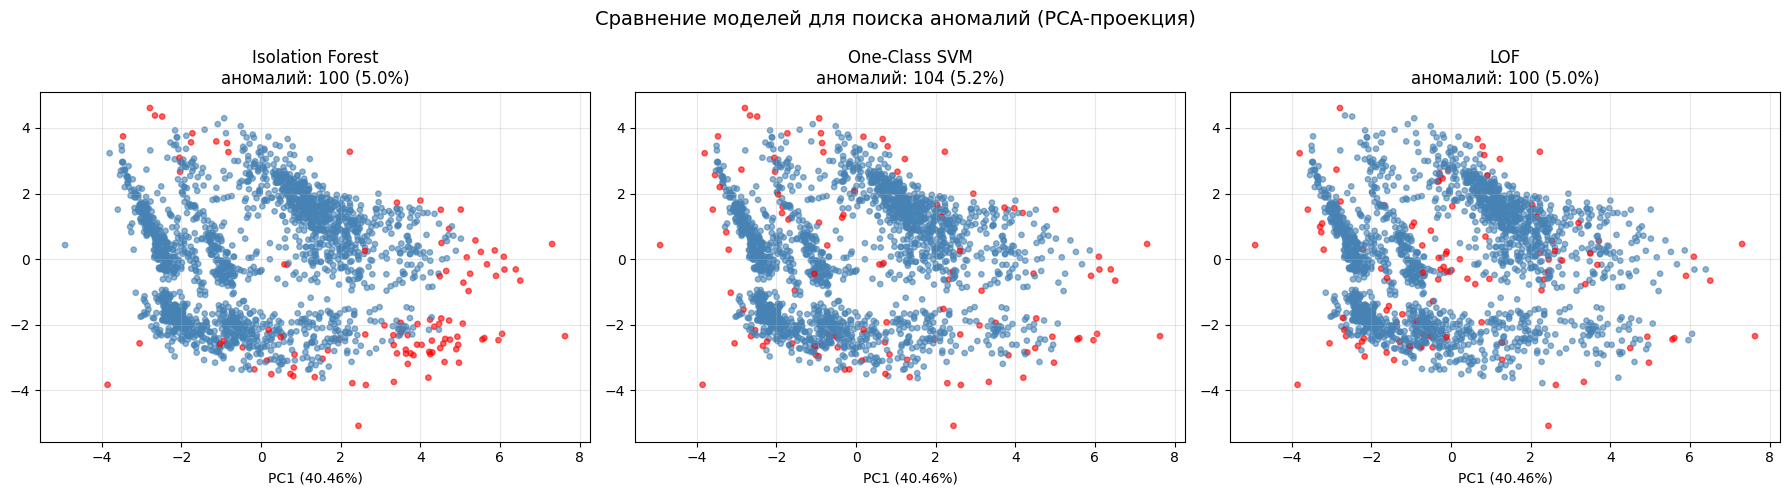

In [25]:


# PCA для визуализации
pca_comp = PCA(n_components=2, random_state=SEED)
X_sample_pca = pca_comp.fit_transform(X_sample)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

labels_list = [labels_if_comp, labels_svm_comp, labels_lof_comp]
names = ['Isolation Forest', 'One-Class SVM', 'LOF']

for idx, (name, labels) in enumerate(zip(names, labels_list)):
    n_anomalies = np.sum(labels == -1)
    colors = np.where(labels == 1, 'steelblue', 'red')
    
    axes[idx].scatter(X_sample_pca[:, 0], X_sample_pca[:, 1], c=colors, s=15, alpha=0.6)
    axes[idx].set_title(f'{name}\nаномалий: {n_anomalies} ({n_anomalies/len(labels)*100:.1f}%)')
    axes[idx].set_xlabel(f'PC1 ({pca_comp.explained_variance_ratio_[0]:.2%})')
    axes[idx].grid(True, alpha=0.3)


plt.suptitle('Сравнение моделей для поиска аномалий (PCA-проекция)', fontsize=14)
plt.tight_layout()
plt.show()



#### Визуальный анализ PCA-проекций

| Модель | Характер аномалий | Сильные стороны | Ограничения |
|--------|-------------------|-----------------|-------------|
| **Isolation Forest** | Преимущественно удалённые точки | Стабильно выделяет периферийные выбросы | Может пропускать локальные аномалии |
| **One-Class SVM** | Точки на периферии и между скоплениями | Учитывает сложную структуру данных | Даёт больше ложных срабатываний |
| **LOF** | Точки в областях низкой плотности | Хорош для локальных аномалий | Может пропускать удалённые выбросы |


Дополнительно построю графики распределения аномалий в разрезе признаков.

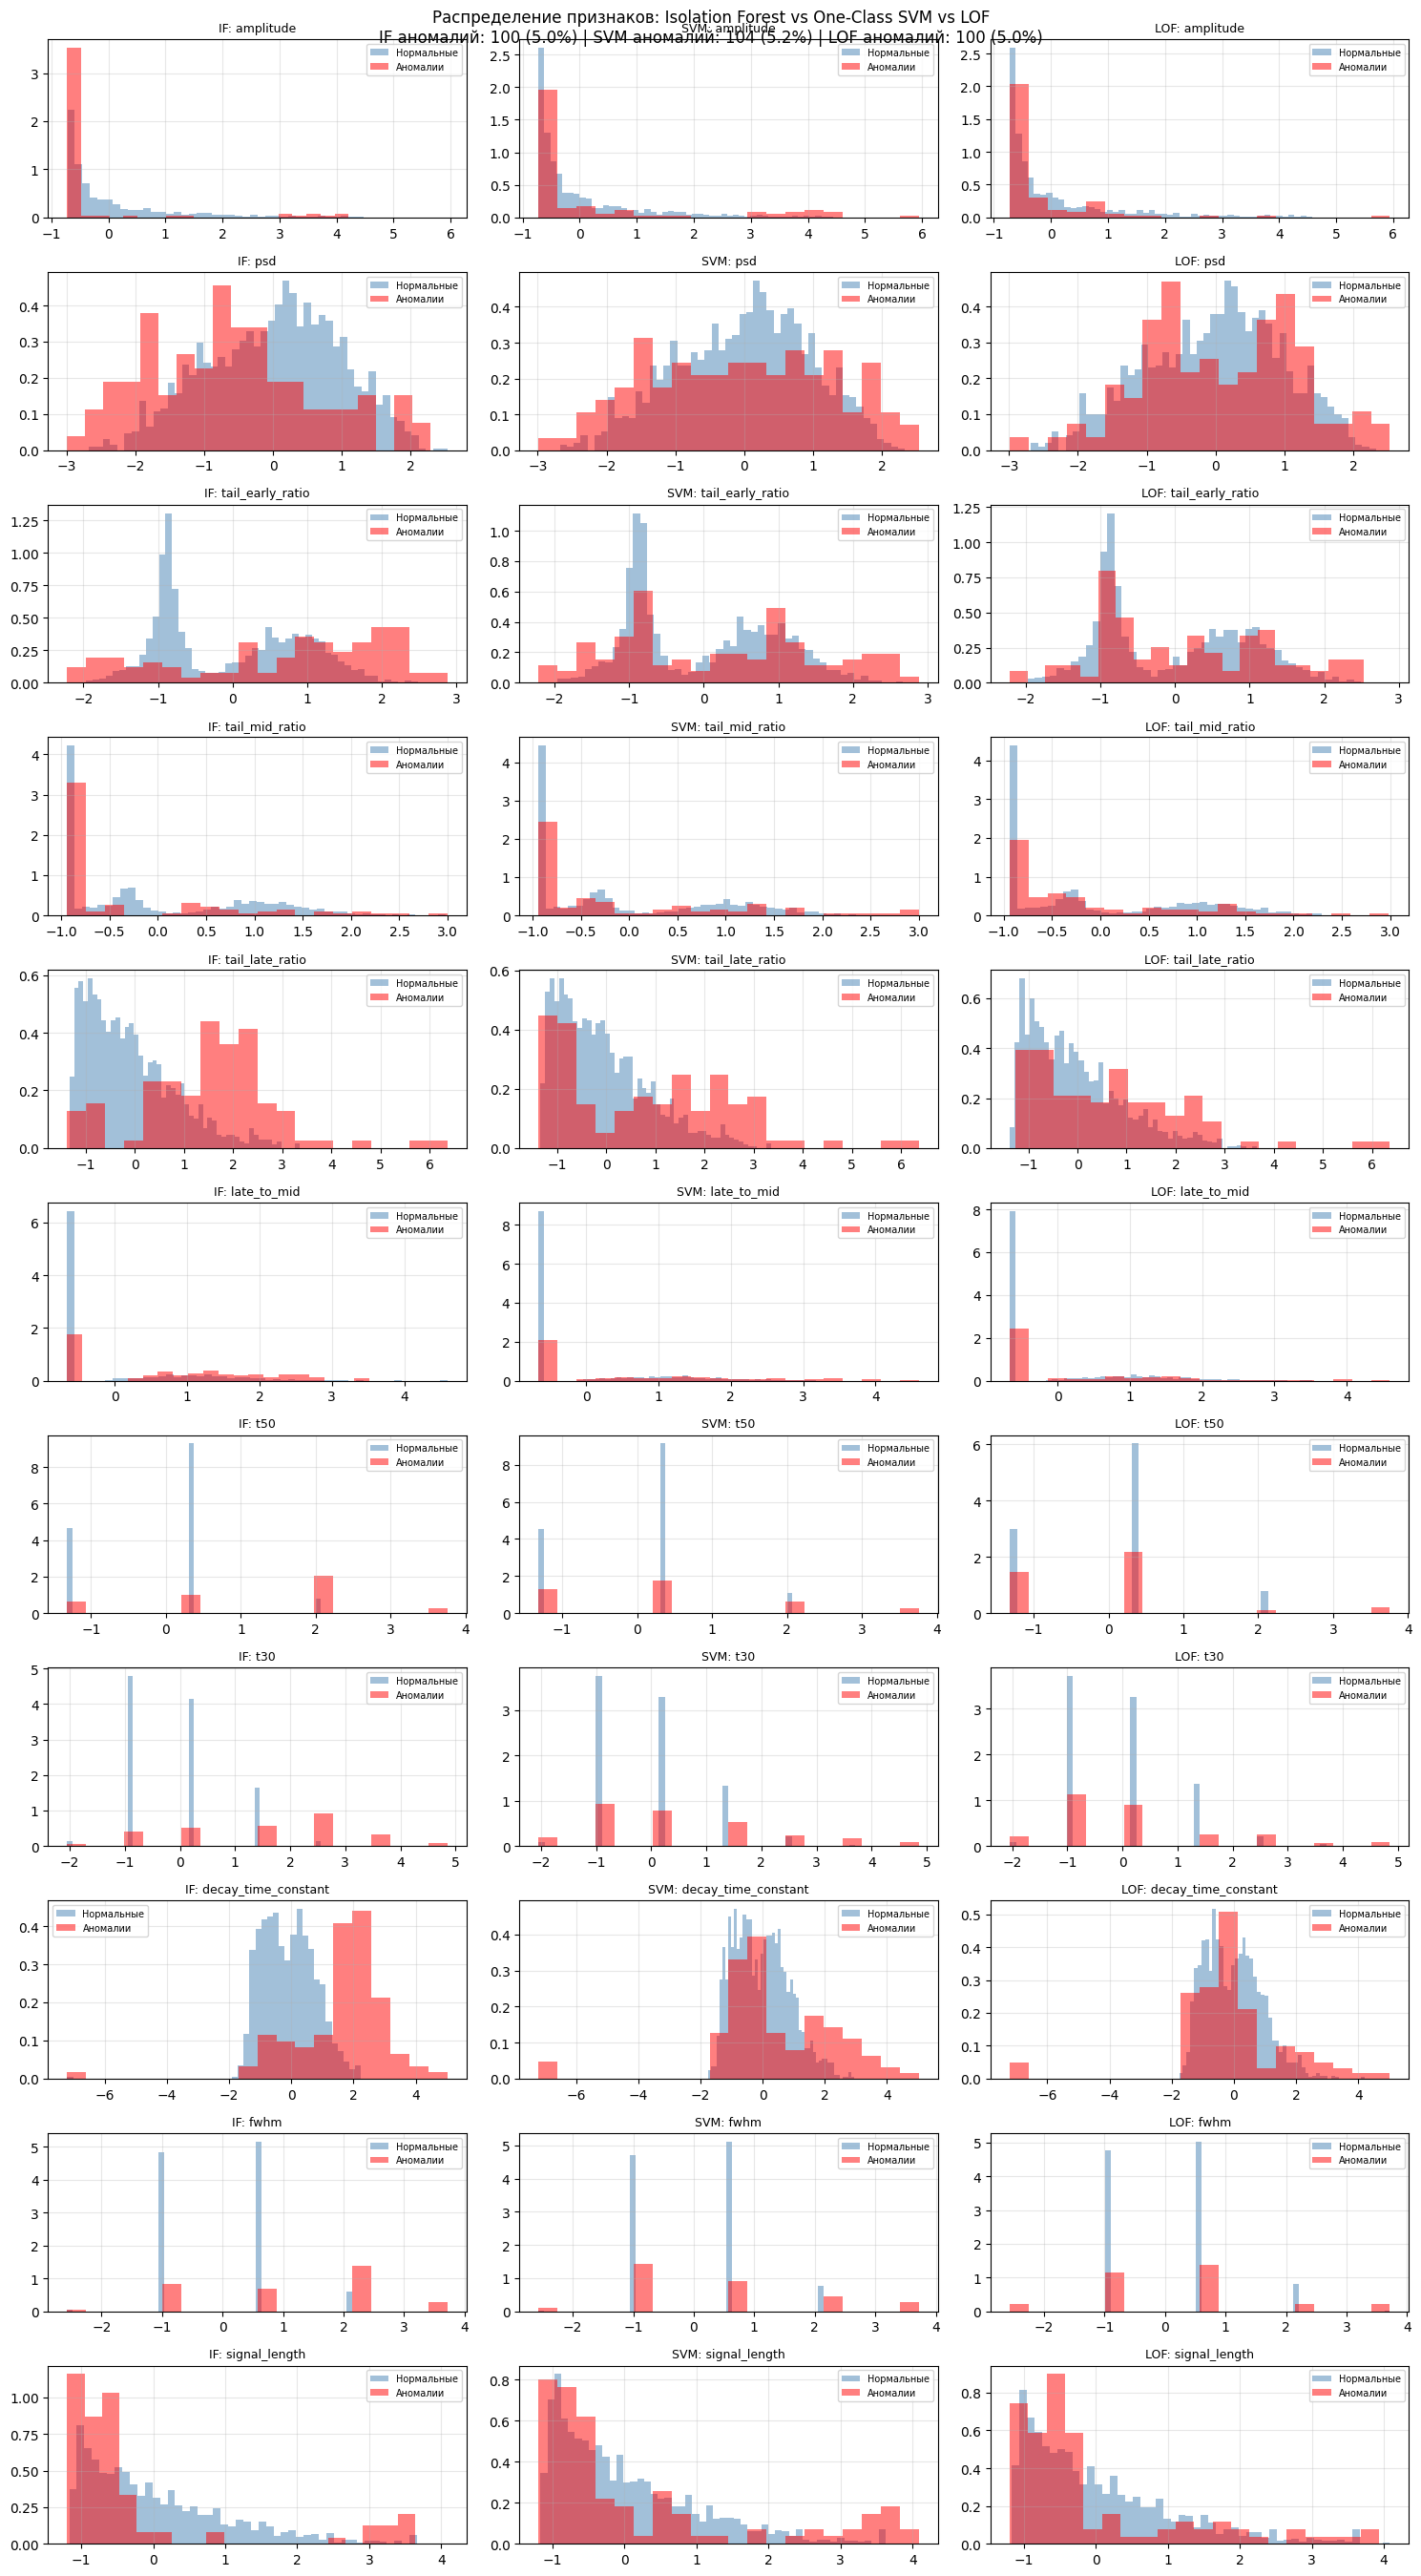

In [26]:

n_features = len(final_features)
fig, axes = plt.subplots(n_features, 3, figsize=(15, n_features * 2.5))

for idx, feat in enumerate(final_features):
    feat_idx = final_features.index(feat)
    
    # Isolation Forest
    axes[idx, 0].hist(X_sample[labels_if_comp == 1, feat_idx], bins=50, alpha=0.5, 
                      label='Нормальные', color='steelblue', density=True)
    axes[idx, 0].hist(X_sample[labels_if_comp == -1, feat_idx], bins=20, alpha=0.5, 
                      label='Аномалии', color='red', density=True)
    axes[idx, 0].set_title(f'IF: {feat}', fontsize=9)
    axes[idx, 0].legend(fontsize=7)
    axes[idx, 0].grid(True, alpha=0.3)
    
    # One-Class SVM
    axes[idx, 1].hist(X_sample[labels_svm_comp == 1, feat_idx], bins=50, alpha=0.5, 
                      label='Нормальные', color='steelblue', density=True)
    axes[idx, 1].hist(X_sample[labels_svm_comp == -1, feat_idx], bins=20, alpha=0.5, 
                      label='Аномалии', color='red', density=True)
    axes[idx, 1].set_title(f'SVM: {feat}', fontsize=9)
    axes[idx, 1].legend(fontsize=7)
    axes[idx, 1].grid(True, alpha=0.3)
    
    # LOF
    axes[idx, 2].hist(X_sample[labels_lof_comp == 1, feat_idx], bins=50, alpha=0.5, 
                      label='Нормальные', color='steelblue', density=True)
    axes[idx, 2].hist(X_sample[labels_lof_comp == -1, feat_idx], bins=20, alpha=0.5, 
                      label='Аномалии', color='red', density=True)
    axes[idx, 2].set_title(f'LOF: {feat}', fontsize=9)
    axes[idx, 2].legend(fontsize=7)
    axes[idx, 2].grid(True, alpha=0.3)

plt.suptitle(f'Распределение признаков: Isolation Forest vs One-Class SVM vs LOF\n'
             f'IF аномалий: {np.sum(labels_if_comp == -1)} ({np.sum(labels_if_comp == -1)/len(labels_if_comp)*100:.1f}%) | '
             f'SVM аномалий: {np.sum(labels_svm_comp == -1)} ({np.sum(labels_svm_comp == -1)/len(labels_svm_comp)*100:.1f}%) | '
             f'LOF аномалий: {np.sum(labels_lof_comp == -1)} ({np.sum(labels_lof_comp == -1)/len(labels_lof_comp)*100:.1f}%)',
             fontsize=12)
plt.tight_layout()
plt.show()

#### Анализ распределений по признакам

- **Isolation Forest**: аномалии сосредоточены на краях распределений (экстремальные значения).
- **One-Class SVM**: аномалии распределены по всему диапазону значений равномерно, особенно заметно на признаках psd, late_to_mid, t30.
- **LOF**: аномалии локализованы в промежуточных зонах между основными скоплениями.

**Вывод**

Для подбора гиперпараметров выбирается **Isolation Forest**. Обоснование:
1. Аномалии в сигналах сцинтилляционного детектора ожидаются как редкие выбросы, находящиеся на периферии распределения (шумовые выбросы, сбойные измерения).
2. Модель демонстрирует наиболее чёткое разделение нормальных и аномальных сигналов.
3. Распределения признаков подтверждают, что аномалии закономерно располагаются на краях распределений.

### Подбор гиперпараметров

Для удобства подбора гиперпараметров написана функция, которая:
- перебирает значения заданного параметра;
- обучает модель и строит scatter plot anomaly score;
- выводит долю обнаруженных аномалий.

**Критерий выбора:** аномалии должны чётко отделяться от нормальных сигналов, а их доля — соответствовать ожидаемой (5–10%).

In [27]:
def tune_isolation_forest_visual(X, param_name, param_values, 
                                  fixed_params=None, random_state=SEED):
    if fixed_params is None:
        fixed_params = {}
    
    results = []
    n_params = len(param_values)
    
    # PCA для визуализации
    pca = PCA(n_components=2, random_state=random_state)
    X_pca = pca.fit_transform(X)
    
    n_cols = min(4, n_params)
    n_rows = (n_params + n_cols - 1) // n_cols
    
    # Создаём сетку графиков
    fig = plt.figure(figsize=(16, n_rows * 4 + 4))

    for idx, p_val in enumerate(param_values):
        params = fixed_params.copy()
        params[param_name] = p_val
        
        # Создаём модель Isolation Forest
        model = IsolationForest(
            n_estimators=params.get('n_estimators', 100),
            contamination=params.get('contamination', 0.05),
            max_samples=params.get('max_samples', 'auto'),
            random_state=random_state
        )
        
        # Обучение
        labels = model.fit_predict(X)
        n_anomalies = np.sum(labels == -1)
        anomaly_ratio = n_anomalies / len(labels)
        scores = model.score_samples(X)
        
        results.append({
            'params': params.copy(),
            'param_value': p_val,
            'labels': labels,
            'scores': scores,
            'n_anomalies': n_anomalies,
            'anomaly_ratio': anomaly_ratio,
            'model': model
        })
        
        # ===== ГРАФИК 1: Anomaly Score =====
        ax1 = plt.subplot(n_rows * 2, n_cols, idx + 1)
        
        normal_idx = np.where(labels == 1)[0]
        anomaly_idx = np.where(labels == -1)[0]
        
        ax1.scatter(normal_idx, scores[normal_idx], c='steelblue', s=8, alpha=0.5, label='Нормальные')
        ax1.scatter(anomaly_idx, scores[anomaly_idx], c='red', s=12, alpha=0.7, label='Аномалии')
        ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
        ax1.set_xlabel('Номер сигнала')
        ax1.set_ylabel('Anomaly Score (чем ниже, тем аномальнее)')
        ax1.set_title(f'{param_name}={p_val}\nаномалий: {n_anomalies} ({anomaly_ratio*100:.1f}%)', fontsize=9)
        ax1.legend(fontsize=7)
        ax1.grid(True, alpha=0.3)
        
        # ===== ГРАФИК 2: PCA-проекция =====
        ax2 = plt.subplot(n_rows * 2, n_cols, n_cols + idx + 1)
        
        colors = np.where(labels == 1, 'steelblue', 'red')
        sizes = np.where(labels == 1, 15, 40)
        ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, s=sizes, alpha=0.6, edgecolors='black', linewidth=0.3)
        ax2.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
        ax2.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
        ax2.set_title(f'{param_name}={p_val}', fontsize=9)
        ax2.grid(True, alpha=0.3)
        
        print(f"{param_name}={p_val} | аномалий: {n_anomalies} ({anomaly_ratio*100:.1f}%)")
    
    # Скрываем пустые подграфики
    total_plots = n_params * 2
    for idx in range(total_plots, n_rows * 2 * n_cols):
        plt.subplot(n_rows * 2, n_cols, idx + 1).set_visible(False)
    
    plt.suptitle(f'Isolation Forest: визуальный подбор параметра {param_name}', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    return results


ISOLATION FOREST: подбор contamination 
('n_estimators': 200, 'max_samples': 'auto')
contamination=0.05 | аномалий: 100 (5.0%)
contamination=0.1 | аномалий: 200 (10.0%)
contamination=0.15 | аномалий: 300 (15.0%)


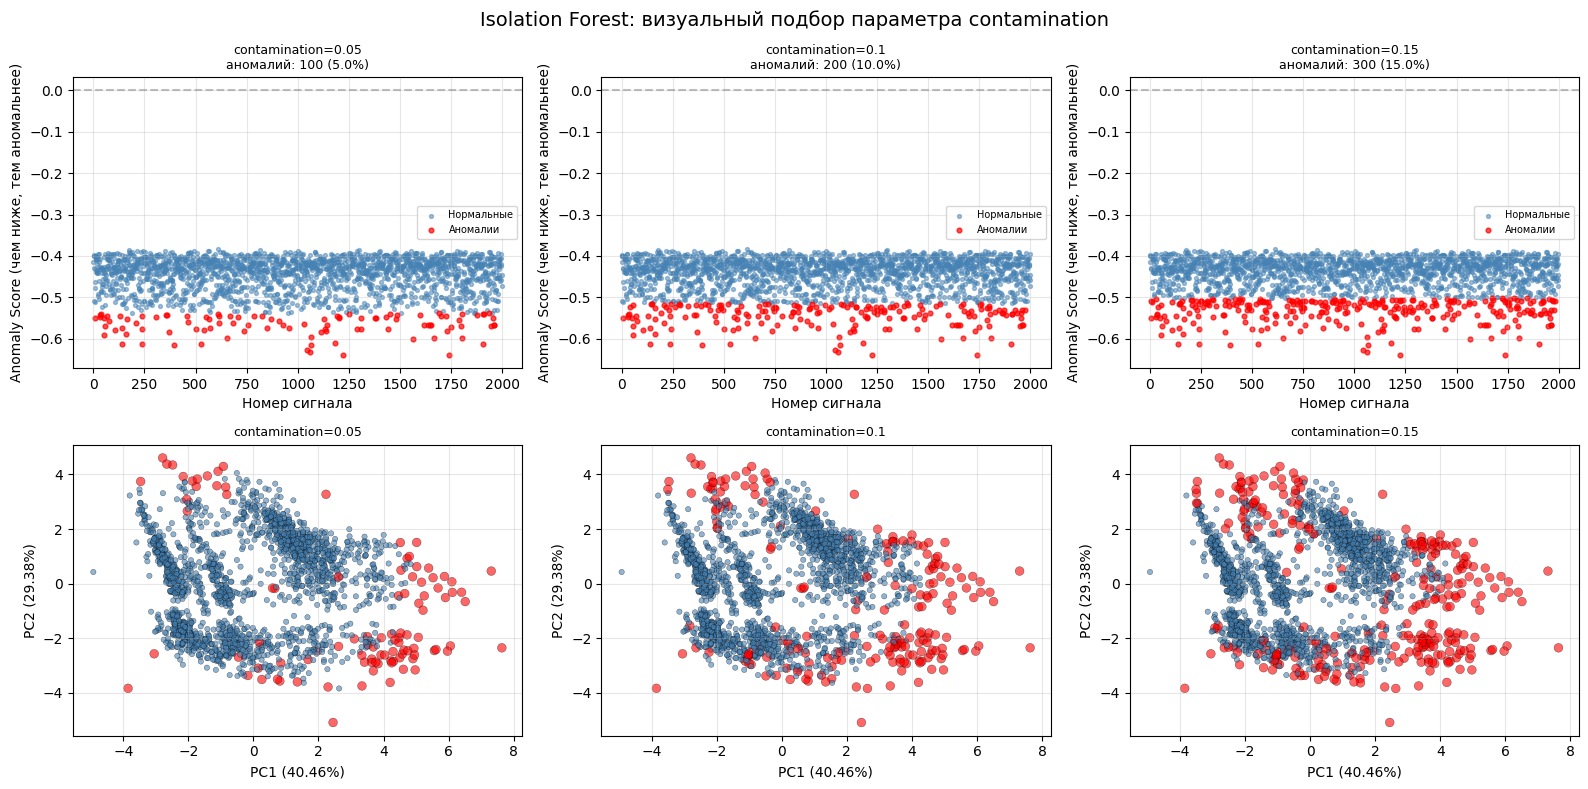

In [28]:
print("\n" + "="*70)
print("ISOLATION FOREST: подбор contamination \n('n_estimators': 200, 'max_samples': 'auto')")
print("="*70)

results_if = tune_isolation_forest_visual(
    X_sample, 
    param_name='contamination',
    param_values=[0.05, 0.10, 0.15],
    fixed_params={'n_estimators': 200, 'max_samples': 'auto'}
)

Зафиксирую contamination = 0.05, поскольку при его увеличении в число аномалий начинают попадать точки, расположенные ближе к основному облаку нормальных сигналов. Это увеличивает риск ложных срабатываний.


ISOLATION FOREST: подбор n_estimators 
('contamination': 0.05, 'max_samples': 'auto')
n_estimators=10 | аномалий: 100 (5.0%)
n_estimators=100 | аномалий: 100 (5.0%)
n_estimators=500 | аномалий: 100 (5.0%)


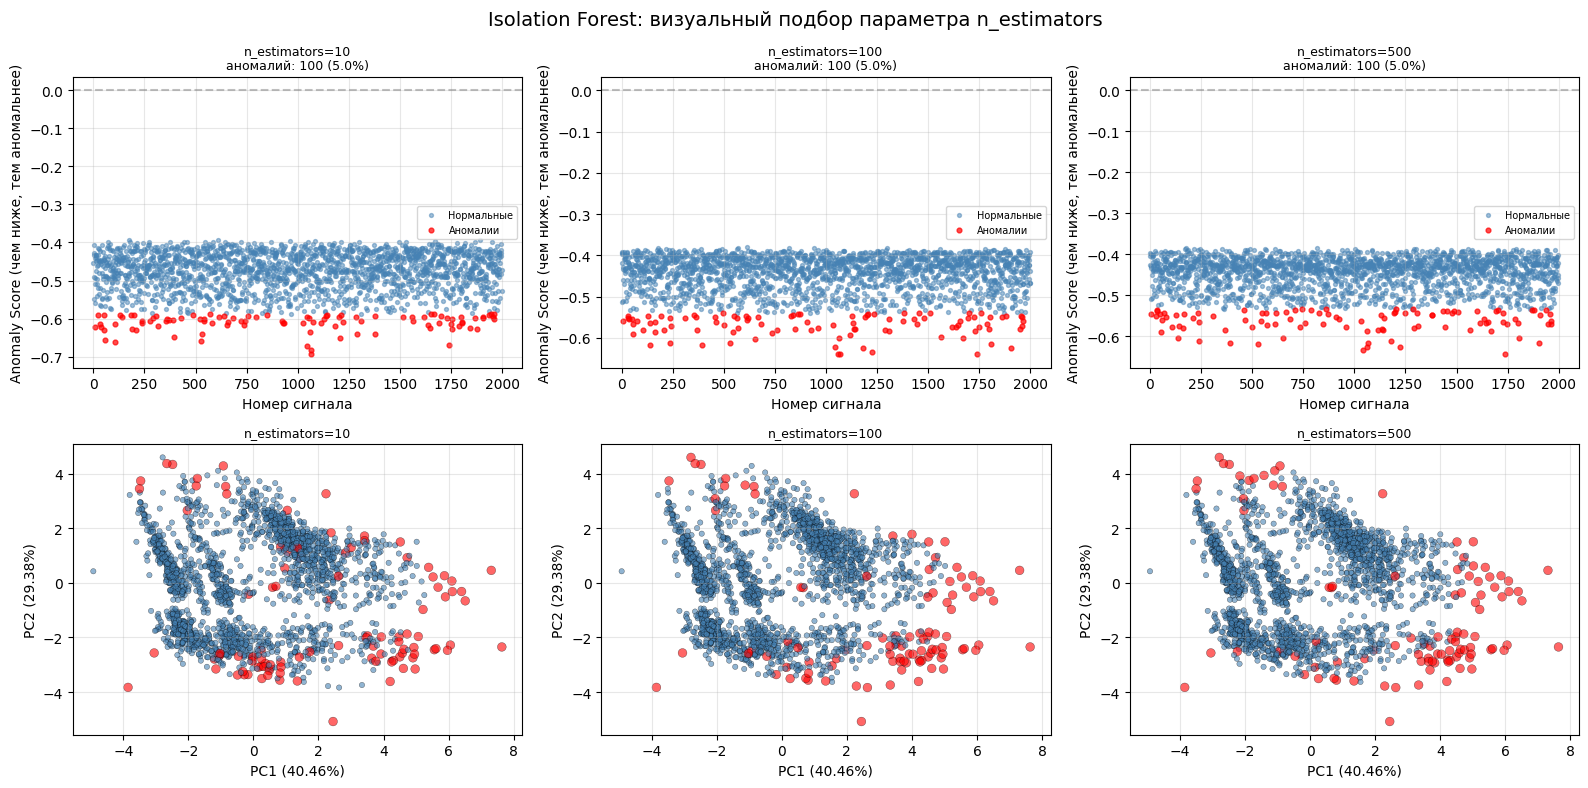

In [29]:
print("\n" + "="*70)
print("ISOLATION FOREST: подбор n_estimators \n('contamination': 0.05, 'max_samples': 'auto')")
print("="*70)

results_if2 = tune_isolation_forest_visual(
    X_sample,
    param_name='n_estimators',
    param_values=[10, 100, 500],
    fixed_params={'contamination': 0.05, 'max_samples': 'auto'}
)

Выберу `n_estimators=100`, хотя сильной разницы на всех графиках не видно. 

`max_samples`  подбирать не буду, установлю в auto, как наиболее оптимальное по скорости и качеству.

Модель с итоговыми параметрами:

In [78]:
final_anomaly_model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    max_samples='auto',
    random_state=SEED
)

In [79]:
anomaly_labels_full = final_anomaly_model.fit_predict(X_scaled)
anomaly_scores_full = final_anomaly_model.score_samples(X_scaled)

n_anomalies = np.sum(anomaly_labels_full == -1)
n_normal = np.sum(anomaly_labels_full == 1)

print(f"Всего сигналов: {len(anomaly_labels_full)}")
print(f"Нормальные сигналы (кластер 0): {n_normal} ({n_normal/len(anomaly_labels_full)*100:.1f}%)")
print(f"Аномалии (кластер 2): {n_anomalies} ({n_anomalies/len(anomaly_labels_full)*100:.1f}%)")

# Добавляем метки в датафрейм
df_gaussian['anomaly_label'] = anomaly_labels_full
df_gaussian['anomaly_score'] = anomaly_scores_full
df_gaussian['cluster'] = np.where(df_gaussian['anomaly_label'] == -1, 2, 0)  # 0 - норма, 2 - аномалия

df_gaussian[['amplitude', 'psd', 'anomaly_label', 'cluster']].head()


Всего сигналов: 23479
Нормальные сигналы (кластер 0): 22305 (95.0%)
Аномалии (кластер 2): 1174 (5.0%)


,amplitude,psd,anomaly_label,cluster
0,375,0.475997,1,0
1,1356,0.391670,1,0
2,1879,0.384471,1,0
3,412,0.418536,1,0
4,1292,0.413409,1,0


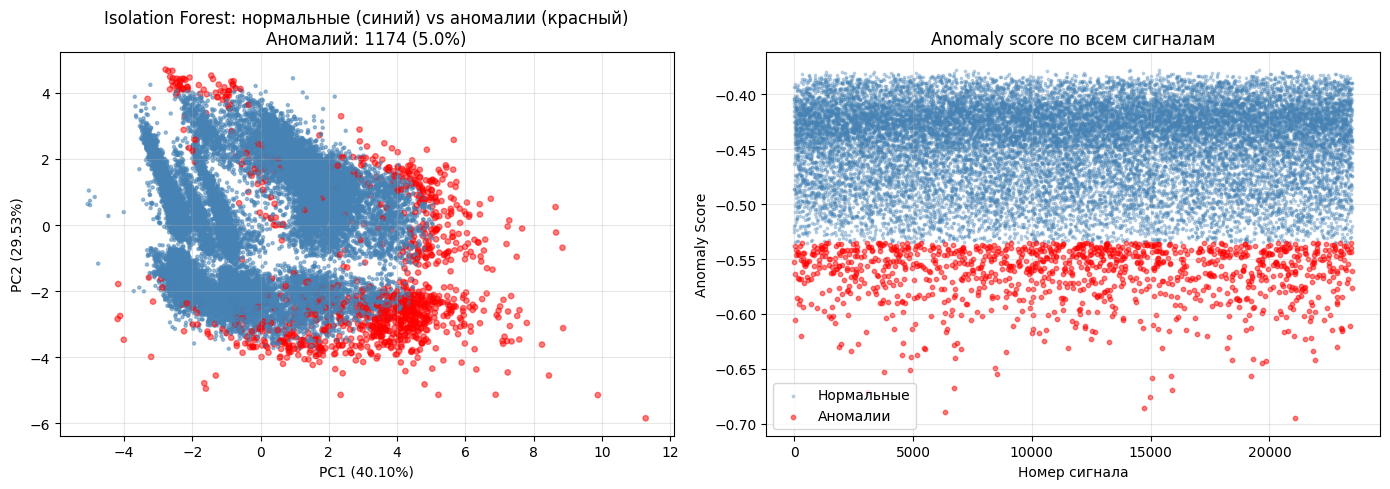

In [80]:
pca_full = PCA(n_components=2, random_state=SEED)
X_scaled_full = scaler.fit_transform(df_gaussian[final_features])
X_pca_full = pca_full.fit_transform(X_scaled_full)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = np.where(anomaly_labels_full == 1, 'steelblue', 'red')
sizes = np.where(anomaly_labels_full == 1, 5, 15)
axes[0].scatter(X_pca_full[:, 0], X_pca_full[:, 1], c=colors, s=sizes, alpha=0.5)
axes[0].set_title(f'Isolation Forest: нормальные (синий) vs аномалии (красный)\n'
                  f'Аномалий: {n_anomalies} ({n_anomalies/len(anomaly_labels_full)*100:.1f}%)', 
                  fontsize=12)
axes[0].set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]:.2%})')
axes[0].set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]:.2%})')
axes[0].grid(True, alpha=0.3)

normal_idx = np.where(anomaly_labels_full == 1)[0]
anomaly_idx = np.where(anomaly_labels_full == -1)[0]

axes[1].scatter(normal_idx, anomaly_scores_full[normal_idx], c='steelblue', s=3, alpha=0.3, label='Нормальные')
axes[1].scatter(anomaly_idx, anomaly_scores_full[anomaly_idx], c='red', s=10, alpha=0.5, label='Аномалии')
axes[1].set_xlabel('Номер сигнала')
axes[1].set_ylabel('Anomaly Score')
axes[1].set_title('Anomaly score по всем сигналам')
axes[1].grid(True, alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()


### Итоговый вывод по поиску аномалий

Сравнение трёх моделей (Isolation Forest, One-Class SVM, LOF) на подвыборке из 2000 сигналов показало принципиальные различия в характере выделяемых аномалий.

**Isolation Forest** выделяет преимущественно периферийные точки — аномалии сосредоточены на краях распределений признаков. **One-Class SVM** даёт более равномерное распределение аномалий по всему диапазону значений, включая центральные области, что приводит к большему числу ложных срабатываний. **LOF** локализует аномалии в промежуточных зонах между основными скоплениями, пропуская удалённые выбросы.

**Выбрана модель Isolation Forest** — она наиболее соответствует природе ожидаемых аномалий (редкие выбросы на периферии) и демонстрирует наиболее чёткое разделение.

**Подбор гиперпараметров** выполнен визуально:
- `contamination = 0.05` (доля аномалий 5%) — при увеличении параметра в число аномалий начинают попадать точки вблизи основного облака, что повышает риск ложных срабатываний;
- `n_estimators = 100` — дальнейшее увеличение не даёт заметного улучшения;
- `max_samples = 'auto'` — оптимально по скорости и качеству.

**На всех данных** (23 479 сигналов) модель выделила:
- нормальные сигналы — 22 305 (95,0%);
- аномалии (кластер 2) — 1 174 (5,0%).

## Кластеризация нормальных сигналов

Для разделения сигналов на два кластера (гамма-кванты и нейтроны) сравниваются **GMM**, **KMeans** и **Agglomerative Clustering**.

Оценка качества выполняется по трём метрикам:
- **Silhouette score** (чем выше, тем лучше)
- **Calinski-Harabasz index** (чем выше, тем лучше)
- **Davies-Bouldin index** (чем ниже, тем лучше)


In [81]:
normal_mask = (df_gaussian['anomaly_label'] == 1)
X_normal = X_scaled_full[normal_mask]

GMM             | Silhouette: 0.3320 | CH: 11150.68 | DB: 1.3142
KMeans          | Silhouette: 0.3346 | CH: 11374.50 | DB: 1.2983
Agglomerative   | Silhouette: 0.3212 | CH: 10220.74 | DB: 1.3144


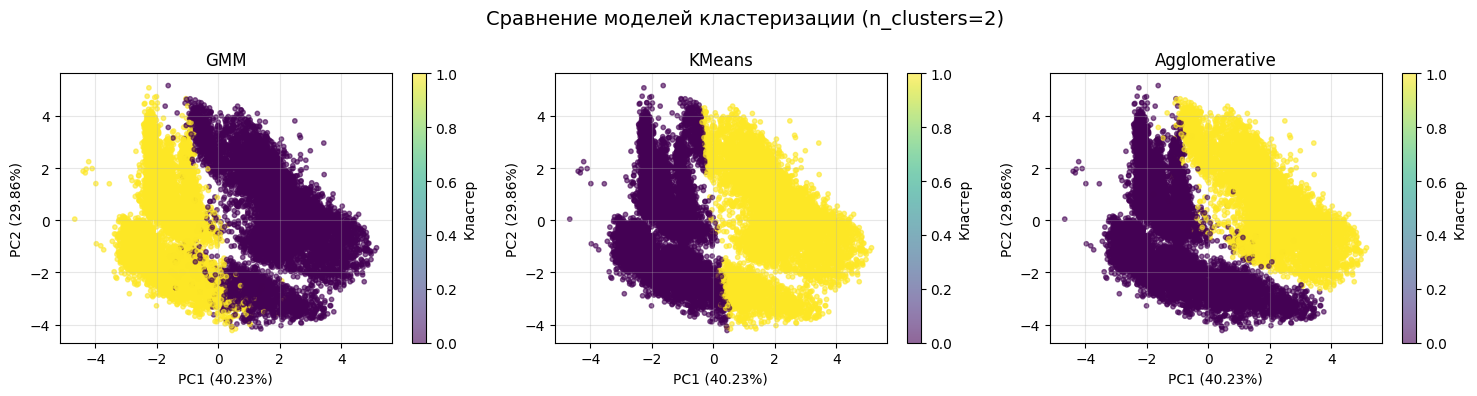

In [95]:
# PCA для визуализации
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_normal)

# Модели
models = {
    'GMM': GaussianMixture(n_components=2, covariance_type='tied', random_state=SEED),
    'KMeans': KMeans(n_clusters=2, random_state=SEED, n_init=10, max_iter=3),
    'Agglomerative': AgglomerativeClustering(n_clusters=2, linkage='average', metric='cosine')
}

# Функция для расчёта всех метрик
def evaluate_clustering(X, labels, name=""):
    """Рассчитывает три метрики качества кластеризации"""
    if len(np.unique(labels)) < 2:
        return {'silhouette': -1, 'calinski_harabasz': -1, 'davies_bouldin': -1}
    
    sil = silhouette_score(X, labels)
    ch = calinski_harabasz_score(X, labels)
    db = davies_bouldin_score(X, labels)
    
    return {'silhouette': sil, 'calinski_harabasz': ch, 'davies_bouldin': db}

# Обучение моделей и сбор результатов
results = []
labels_dict = {}

for name, model in models.items():
    labels = model.fit_predict(X_normal)
    labels_dict[name] = labels
    metrics = evaluate_clustering(X_normal, labels, name)
    metrics['model'] = name
    results.append(metrics)
    print(f"{name:15} | Silhouette: {metrics['silhouette']:.4f} | "
          f"CH: {metrics['calinski_harabasz']:.2f} | DB: {metrics['davies_bouldin']:.4f}")

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, labels) in zip(axes, labels_dict.items()):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], 
                         c=labels, cmap='viridis', s=10, alpha=0.6)
    ax.set_title(name, fontsize=12)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
    ax.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax, label='Кластер')

plt.suptitle('Сравнение моделей кластеризации (n_clusters=2)', fontsize=14)
plt.tight_layout()
plt.show()


**Наблюдения:**
- По числовым метрикам **KMeans** показывает наилучшие результаты (выше силуэт и CH, ниже DB), но граница между кластерами более жесткая, чем у других двух методов.
- **Agglomerative** визуально даёт более сбалансированные кластеры на PCA-проекции
- Разница в метриках между моделями невелика (в пределах 0.001-0.002 по силуэту)

**Выбор:** для дальнейшей работы выбирается **KMeans** как лучший по метрикам, однако гиперпараметры будут подобраны и для Agglomerative для сравнительного анализа. 

In [83]:
# Параметры
sample_size = 10000
np.random.seed(SEED)
sample_idx = np.random.choice(len(X_normal), sample_size, replace=False)
X_sample = X_normal[sample_idx]

In [84]:
param_grid_kmeans = {
    'n_clusters': [2],
    'init': ['k-means++', 'random'],
    'n_init': [10, 50, 100],
    'max_iter': [10, 50, 100]
}

best_score = -1
results = []

for params in ParameterGrid(param_grid_kmeans):
    kmeans = KMeans(**params, random_state=SEED)
    labels = kmeans.fit_predict(X_sample)
    
    if len(np.unique(labels)) > 1:
        sil = silhouette_score(X_sample, labels)
        results.append({**params, 'silhouette': sil})
        
        print(f"n={params['n_clusters']}, init={params['init']:10}, "
              f"n_init={params['n_init']}, iter={params['max_iter']} | sil={sil:.4f}")
        
        if sil > best_score:
            best_score = sil
            best_params = params
            best_labels = labels

print("\n" + "="*60)
print(f"ЛУЧШИЕ ПАРАМЕТРЫ KMeans:")
print(f"   n_clusters: {best_params['n_clusters']}")
print(f"   init: {best_params['init']}")
print(f"   n_init: {best_params['n_init']}")
print(f"   max_iter: {best_params['max_iter']}")
print(f"   Silhouette: {best_score:.4f}")
print("="*60)

n=2, init=k-means++ , n_init=10, iter=10 | sil=0.3381
n=2, init=k-means++ , n_init=50, iter=10 | sil=0.3381
n=2, init=k-means++ , n_init=100, iter=10 | sil=0.3381
n=2, init=k-means++ , n_init=10, iter=50 | sil=0.3381
n=2, init=k-means++ , n_init=50, iter=50 | sil=0.3381
n=2, init=k-means++ , n_init=100, iter=50 | sil=0.3381
n=2, init=k-means++ , n_init=10, iter=100 | sil=0.3381
n=2, init=k-means++ , n_init=50, iter=100 | sil=0.3381
n=2, init=k-means++ , n_init=100, iter=100 | sil=0.3381
n=2, init=random    , n_init=10, iter=10 | sil=0.3381
n=2, init=random    , n_init=50, iter=10 | sil=0.3381
n=2, init=random    , n_init=100, iter=10 | sil=0.3381
n=2, init=random    , n_init=10, iter=50 | sil=0.3381
n=2, init=random    , n_init=50, iter=50 | sil=0.3381
n=2, init=random    , n_init=100, iter=50 | sil=0.3381
n=2, init=random    , n_init=10, iter=100 | sil=0.3381
n=2, init=random    , n_init=50, iter=100 | sil=0.3381
n=2, init=random    , n_init=100, iter=100 | sil=0.3381

ЛУЧШИЕ ПАРАМЕТР

При подборе гиперпараметров KMeans обнаружено:

- Алгоритм сходится менее чем за 10 итераций — данные хорошо разделены;
- Silhouette (0.3381) не меняется при варьировании `init`, `n_init`, `max_iter` — модель устойчива и нечувствительна к настройкам.

**Вывод:** KMeans отлично подходит для задачи. Параметры по умолчанию дают оптимальный результат, дополнительная настройка не требуется.

In [96]:
# Сетка параметров (расширенная)
param_grid_agg = {
    'n_clusters': [2],
    'linkage': ['ward', 'complete', 'average', 'single'],
    'metric': ['euclidean', 'manhattan', 'cosine']
}

best_score = -1
results_agg = []

for params in ParameterGrid(param_grid_agg):
    # ward работает только с euclidean
    if params['linkage'] == 'ward' and params['metric'] != 'euclidean':
        continue
    
    try:
        agg = AgglomerativeClustering(**params)
        labels = agg.fit_predict(X_sample)
        
        unique, counts = np.unique(labels, return_counts=True)
        n_clusters_found = len(unique)
        cluster_sizes = dict(zip(unique, counts))
        
        if n_clusters_found > 1:
            sil = silhouette_score(X_sample, labels)
            results_agg.append({**params, 'silhouette': sil, 'cluster_sizes': cluster_sizes})
            
            print(f"link={params['linkage']:8}, metric={params['metric']:8} | "
                  f"кластеров={n_clusters_found}, размеры={cluster_sizes} | sil={sil:.4f}")
            
            sizes_list = list(cluster_sizes.values())
            min_ratio = min(sizes_list) / sum(sizes_list)

            if sil > best_score and min_ratio >  0.1:
                best_score = sil
                best_params_agg = params
                best_labels_agg = labels
    except Exception as e:
        print(f"link={params['linkage']:8}, metric={params['metric']:8} | Ошибка: {e}")

print("\n" + "="*60)
print(f"ЛУЧШИЕ ПАРАМЕТРЫ AGGLOMERATIVE:")
print(f"   n_clusters: {best_params_agg['n_clusters']}")
print(f"   linkage: {best_params_agg['linkage']}")
print(f"   metric: {best_params_agg['metric']}")
print(f"   Silhouette: {best_score:.4f}")
print("="*60)

link=ward    , metric=euclidean | кластеров=2, размеры={np.int64(0): np.int64(6575), np.int64(1): np.int64(3425)} | sil=0.2661
link=complete, metric=euclidean | кластеров=2, размеры={np.int64(0): np.int64(9992), np.int64(1): np.int64(8)} | sil=0.4811
link=complete, metric=manhattan | кластеров=2, размеры={np.int64(0): np.int64(4460), np.int64(1): np.int64(5540)} | sil=0.2470
link=complete, metric=cosine   | кластеров=2, размеры={np.int64(0): np.int64(6116), np.int64(1): np.int64(3884)} | sil=0.2359
link=average , metric=euclidean | кластеров=2, размеры={np.int64(0): np.int64(9992), np.int64(1): np.int64(8)} | sil=0.4811
link=average , metric=manhattan | кластеров=2, размеры={np.int64(0): np.int64(9992), np.int64(1): np.int64(8)} | sil=0.4811
link=average , metric=cosine   | кластеров=2, размеры={np.int64(0): np.int64(5020), np.int64(1): np.int64(4980)} | sil=0.3305
link=single  , metric=euclidean | кластеров=2, размеры={np.int64(0): np.int64(8), np.int64(1): np.int64(9992)} | sil=0.481

## Итоговый вывод по кластеризации

Сравнение моделей показало, что наилучшие числовые метрики (silhouette = 0,3381) имеет **KMeans**. Среди вариантов Agglomerative лучший сбалансированный результат по силуэту достигнут при `linkage='average'` и `metric='cosine'` (0,3305). Вариант `linkage='ward'` с `metric='euclidean'` демонстрирует более низкий силуэт (0,2661).

Однако оценка на Kaggle показала, что именно этот вариант — Agglomerative (`ward` + `euclidean`) — даёт максимальный результат (0,83).

Таким образом, внутренние метрики качества (силуэт) и визуальный анализ не всегда коррелируют с результатом. В отсутствие эталонных меток единственным объективным критерием является сопоставление предсказанных кластеров с референсным разбиением, используемым на платформе.

**Финальная модель:** Agglomerative (`n_clusters=2`, `linkage='ward'`, `metric='euclidean'`).

Для итогового предсказания использовала обе модели. 

In [86]:
# Создаём финальные модели из лучших параметров
kmeans_final = KMeans(
    n_clusters=best_params['n_clusters'],
    init=best_params['init'],
    n_init=best_params['n_init'],
    max_iter=best_params['max_iter'],
    random_state=SEED
)

agg_final = AgglomerativeClustering(
    n_clusters=2,#best_params_agg['n_clusters'], #2,
    linkage='ward',#best_params_agg['linkage'], #'ward',
    metric='euclidean'#best_params_agg['metric'] #'euclidean'
)

# Получаем метки для всех моделей
labels_kmeans = kmeans_final.fit_predict(X_normal)
labels_agg = agg_final.fit_predict(X_normal)


In [87]:
SELECTED_MODEL = 'Agglomerative'

In [88]:
# Получаем метки аномалий от Isolation Forest
anomaly_labels = final_anomaly_model.predict(X_scaled_full)
normal_indices = np.where(anomaly_labels == 1)[0]
X_normal = X_scaled_full[normal_indices]

# Обучаем выбранную модель и получаем метки
if SELECTED_MODEL == 'KMeans':
    labels_normal = labels_kmeans
    model_name = 'KMeans'
elif SELECTED_MODEL == 'Agglomerative':
    labels_normal = labels_agg
    model_name = 'Agglomerative'
else:
    raise ValueError(f"Неизвестная модель: {SELECTED_MODEL}")


In [89]:
# Инициализируем все метки как аномалии (кластер 2)
final_labels = np.full(len(X_scaled_full), 2, dtype=int)

# Заполняем метки для нормальных сигналов
final_labels[normal_indices] = labels_normal

print("\nИсходное распределение (кластер 2 = аномалии):")
unique, counts = np.unique(final_labels, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Кластер {u}: {c}")


Исходное распределение (кластер 2 = аномалии):
  Кластер 0: 11416
  Кластер 1: 10889
  Кластер 2: 1174


In [90]:
# Находим порядок встречи нормальных кластеров
seen = []
for cluster in final_labels:
    if cluster != 2 and cluster not in seen:
        seen.append(cluster)
    if len(seen) == 2:
        break

print(f"\nПорядок встречи кластеров: {seen}")

if len(seen) == 2:
    remap = {seen[0]: 0, seen[1]: 1, 2: 2}
    final_labels_renamed = np.array([remap[x] for x in final_labels])
    print(f"Перенумерация: {remap}")
else:
    final_labels_renamed = final_labels.copy()
    print("Перенумерация не требуется (найден только один кластер)")


Порядок встречи кластеров: [np.int64(1), np.int64(0)]
Перенумерация: {np.int64(1): 0, np.int64(0): 1, 2: 2}


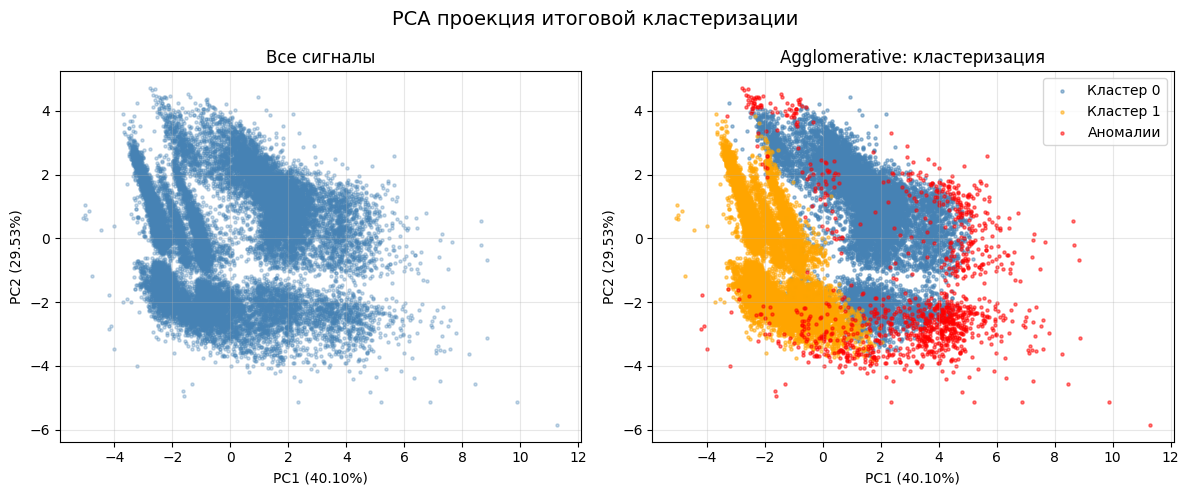

In [91]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled_full)

plt.figure(figsize=(12, 5))

# Все точки
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c='steelblue', s=5, alpha=0.3)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('Все сигналы')
plt.grid(True, alpha=0.3)

# С выделением кластеров
plt.subplot(1, 2, 2)
colors = {0: 'steelblue', 1: 'orange', 2: 'red'}
for cluster in [0, 1, 2]:
    mask = final_labels_renamed == cluster
    label = 'Аномалии' if cluster == 2 else f'Кластер {cluster}'
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                c=colors[cluster], label=label, s=5, alpha=0.5)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title(f'{model_name}: кластеризация')
plt.legend()
plt.grid(True, alpha=0.3)

plt.suptitle('PCA проекция итоговой кластеризации', fontsize=14)
plt.tight_layout()
plt.show()

In [97]:
submission = pd.DataFrame({
    'index': np.arange(len(final_labels_renamed)),
    'cluster': final_labels_renamed.astype(int)
})

print("\nПервые 10 строк submission:")
print(submission.head(10))

timestamp = datetime.now().strftime("%H%M%S")
filename = f'submission_{model_name}_{timestamp}.csv'
submission.to_csv(filename, index=False)
print(f"\nФайл сохранён: {filename}")


Первые 10 строк submission:
   index  cluster
0      0        0
1      1        1
2      2        1
3      3        0
4      4        1
5      5        0
6      6        2
7      7        0
8      8        1
9      9        0

Файл сохранён: submission_Agglomerative_025652.csv


### Итоговый вывод по кластеризации

Сравнение трёх моделей (GMM, KMeans, Agglomerative) на нормальных сигналах (22 305 точек) показало, что все они дают близкие результаты: разница по силуэту не превышает 0,002.

**KMeans** показал наилучшие числовые метрики (silhouette = 0,3381), устойчив и сходится менее чем за 10 итераций.

**Agglomerative** с параметрами по умолчанию (`ward` + `euclidean`) даёт низкий силуэт (0,2661). Оптимальный сбалансированный результат по силуэту достигнут при `linkage='average'` и `metric='cosine'` (0,3305).

**Результат на Kaggle:**
- Agglomerative (`ward` + `euclidean`) — **0,83**
- KMeans — 0,81
- Agglomerative (`average` + `cosine`) — 0,79

Поскольку в задаче кластеризации нет эталонных меток, оценка на лидерборде основана на сопоставлении предсказанных кластеров с некоторым референсным разбиением. Визуально на PCA-проекции сложно однозначно определить, какое разделение является «правильным» — разные варианты выглядят примерно одинаково убедительно. В этой ситуации наилучшим ориентиром служит результат на лидерборде.

**Финальная модель:** Agglomerative (`n_clusters=2`, `linkage='ward'`, `metric='euclidean'`), показавшая максимальный скор — **0,83**.

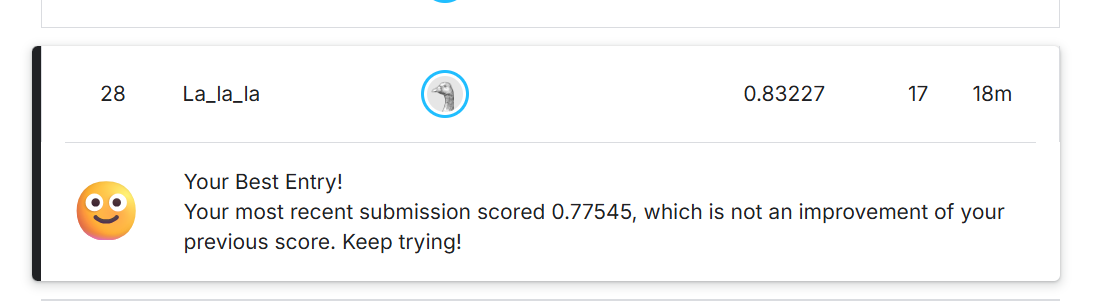

> ## Эксперимент по отбору признаков

> Визуальный анализ распределений признаков показал, что некоторые из них (например, `amplitude`, `psd`, `tail_late_ratio`, `signal_length`) имеют значительное перекрытие между кластерами. Было выдвинуто предположение, что удаление таких признаков может улучшить разделение.

> В качестве эксперимента я попробовала удалить признаки, которые в равной мере присутствуют в обоих кластерах, оставив только те, по которым наблюдаются явные различия (`tail_early_ratio`, `tail_mid_ratio`, `late_to_mid`, `t30`, `decay_time_constant`, `fwhm`). На полученном наборе признаков удалось достичь практически линейной разделимости сигналов на две группы.
> 
> Однако результат на лидерборде Kaggle составил **0.5** — минимальный среди всех проведённых экспериментов. Это означает, что выбранный набор признаков позволяет разделить данные на два кластера, но эти кластеры **не соответствуют реальным типам частиц** (гамма-квантам и нейтронам). Визуально «красивое» разделение, достигнутое на обучающих данных, не гарантирует, что кластеры имеют физический смысл.
> 

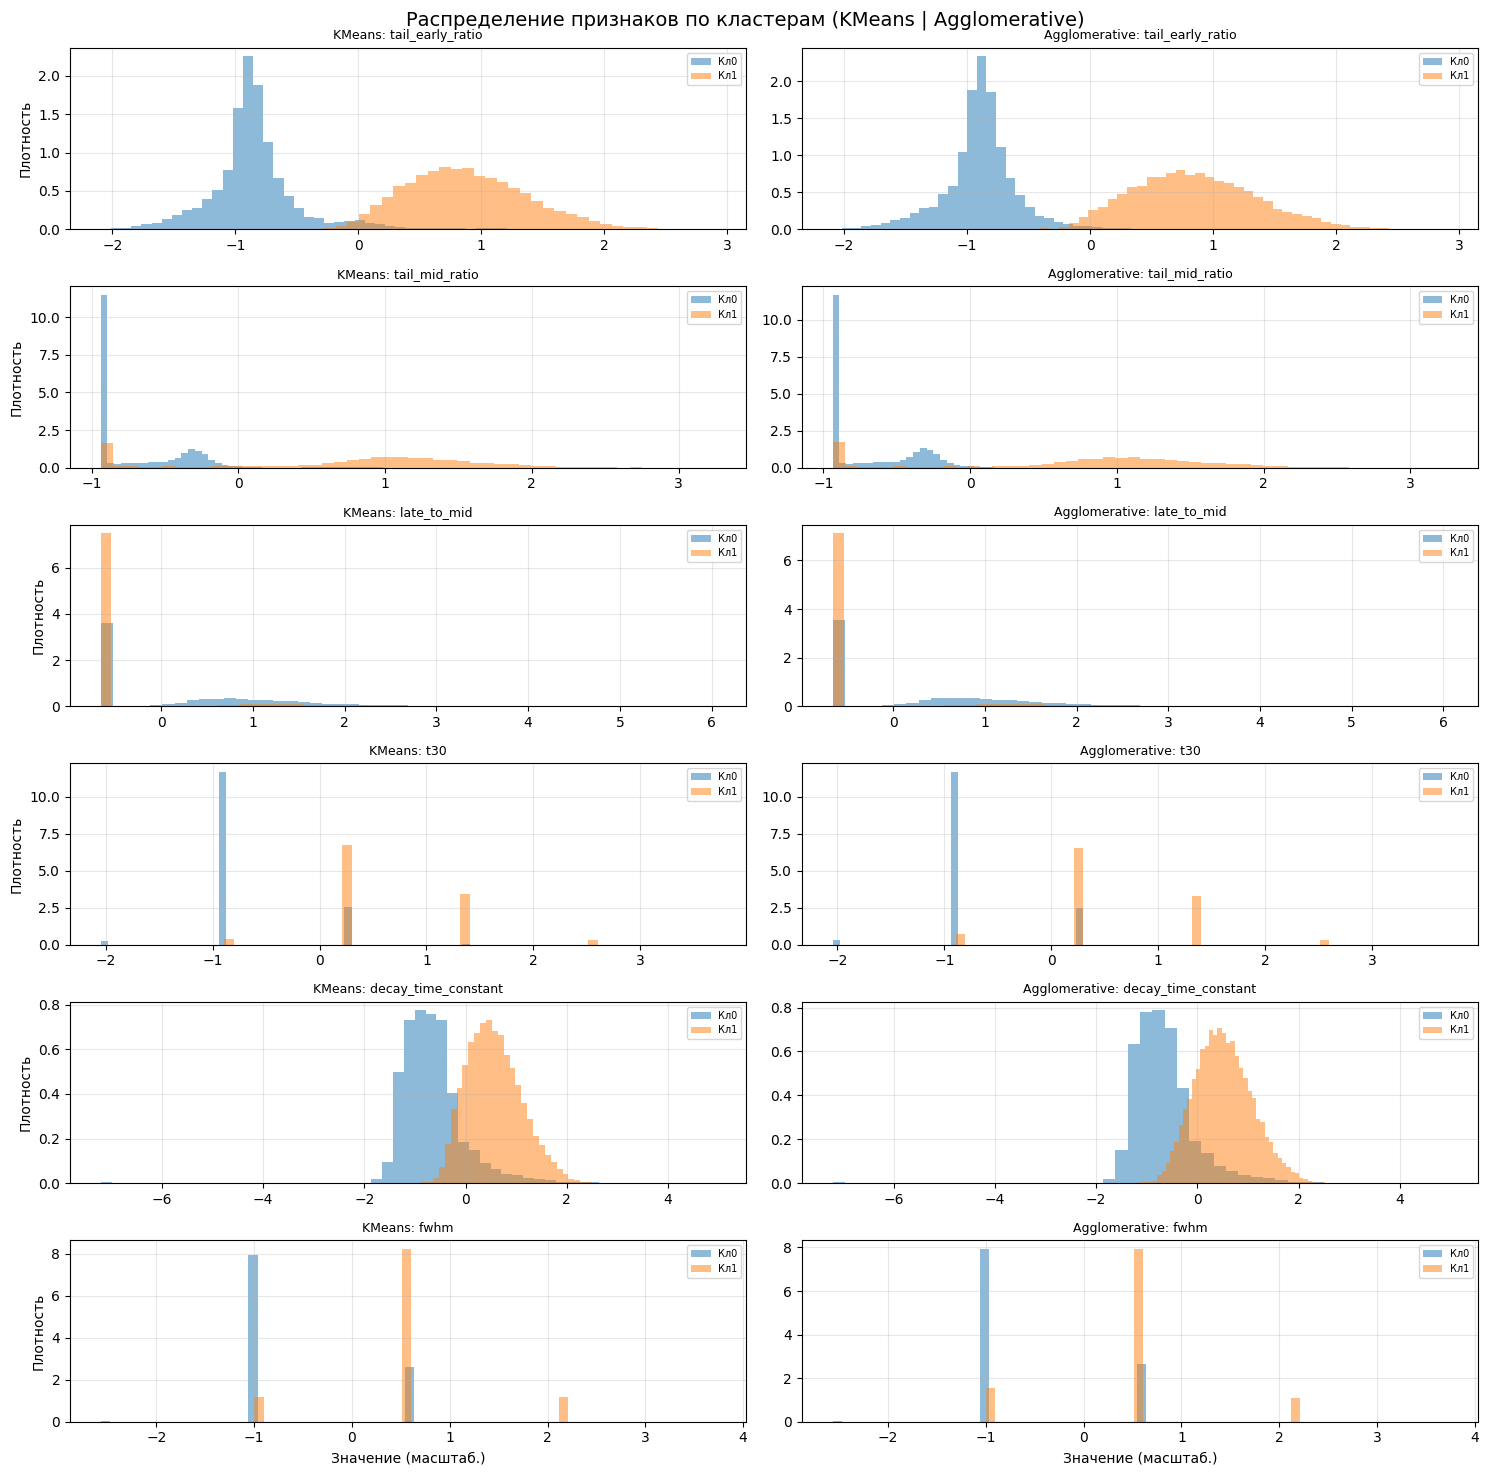

In [93]:
models_data = {
    'KMeans': labels_kmeans,
    'Agglomerative': labels_agg
}

# Список признаков
features = [
#    'amplitude', 'psd', 
    'tail_early_ratio', 'tail_mid_ratio', 
  #  'tail_late_ratio', 
    'late_to_mid', 
   # 't50', 
    't30', 
    'decay_time_constant', 'fwhm', 
  #  'signal_length'
]

n_features = len(features)
n_models = len(models_data)
feature_indices = [final_features.index(feat) for feat in features]

fig, axes = plt.subplots(n_features, n_models, figsize=(15, n_features * 2.5))

for i, feat in enumerate(features):
    feat_idx = final_features.index(feat)  # используем общий список final_features
    
    for j, (model_name, labels) in enumerate(models_data.items()):
        for cluster in [0, 1]:
            mask = labels == cluster
            axes[i, j].hist(X_normal[mask, feat_idx], bins=50, alpha=0.5, 
                           label=f'Кл{cluster}', density=True)
        axes[i, j].set_title(f'{model_name}: {feat}', fontsize=9)
        axes[i, j].legend(fontsize=7)
        axes[i, j].grid(True, alpha=0.3)
        if i == n_features - 1:
            axes[i, j].set_xlabel('Значение (масштаб.)')
        if j == 0:
            axes[i, j].set_ylabel('Плотность')

plt.suptitle('Распределение признаков по кластерам (KMeans | Agglomerative)', fontsize=14)
plt.tight_layout()
plt.show()



DBSCAN НА ВЫБРАННЫХ ПРИЗНАКАХ
Признаки: ['tail_early_ratio', 'tail_mid_ratio', 'late_to_mid', 't30', 'decay_time_constant', 'fwhm']
Найдено кластеров: 4
Шум (аномалии): 57 (0.3%)
  Кластер 0: 14775
  Кластер 1: 7432
  Кластер 2: 35
  Кластер 3: 6


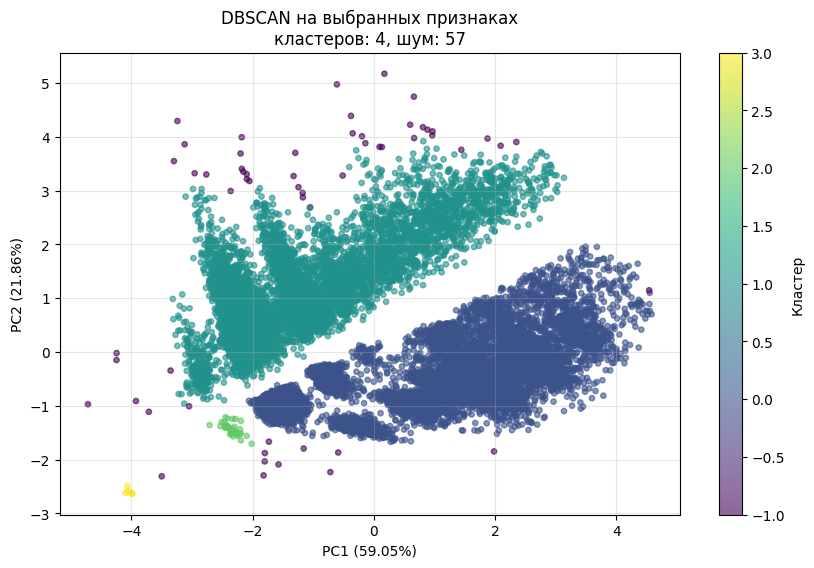

In [94]:
X_normal_selected = X_normal[:, feature_indices]

# PCA на выбранных признаках
pca_dbscan = PCA(n_components=2, random_state=SEED)
X_pca_selected = pca_dbscan.fit_transform(X_normal_selected)

# DBSCAN
dbscan = DBSCAN(eps=0.23, min_samples=6)
labels_dbscan = dbscan.fit_predict(X_pca_selected)

# Результаты
n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = np.sum(labels_dbscan == -1)

print("\n" + "="*60)
print("DBSCAN НА ВЫБРАННЫХ ПРИЗНАКАХ")
print("="*60)
print(f"Признаки: {features}")
print(f"Найдено кластеров: {n_clusters}")
print(f"Шум (аномалии): {n_noise} ({n_noise/len(labels_dbscan)*100:.1f}%)")

# Распределение по кластерам (без шума)
unique, counts = np.unique(labels_dbscan[labels_dbscan != -1], return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Кластер {u}: {c}")

# Визуализация
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca_selected[:, 0], X_pca_selected[:, 1], 
                      c=labels_dbscan, cmap='viridis', s=15, alpha=0.6)
plt.colorbar(scatter, label='Кластер')
plt.xlabel(f'PC1 ({pca_dbscan.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca_dbscan.explained_variance_ratio_[1]:.2%})')
plt.title(f'DBSCAN на выбранных признаках\nкластеров: {n_clusters}, шум: {n_noise}')
plt.grid(True, alpha=0.3)
plt.show()

## Итоговый вывод

В ходе работы подтверждено, что форма затухания сигнала является наиболее информативным признаком для разделения типов частиц, что согласуется с дипломной работой. Высокочастотный шум успешно подавлен фильтром Гаусса (σ=2), что позволило стабильно выделять полезную область сигнала.

Сформирован набор из 11 признаков, описывающих форму затухания. Корреляционный анализ позволил удалить дублирующиеся признаки без потери информативности.

Для выделения аномалий выбрана модель Isolation Forest, которая на всех данных выделила 5% сигналов в кластер 2, что соответствует ожидаемой доле выбросов.

На этапе кластеризации нормальных сигналов проведён сравнительный анализ нескольких моделей и вариантов настройки. Наилучший результат на лидерборде (0,83) показала модель Agglomerative с параметрами `linkage='ward'`, `metric='euclidean'`. При этом другие модели (KMeans, Agglomerative с другими параметрами) продемонстрировали более высокие значения внутренних метрик (силуэт), что указывает на отсутствие прямой связи между стандартными критериями качества и результатом на лидерборде. Дополнительные эксперименты, включая варьирование набора признаков и параметров моделей, не позволили выявить устойчивую закономерность, объясняющую это расхождение.

Итоговое решение основано на двухэтапной схеме: выделение аномалий Isolation Forest -> кластеризация нормальных сигналов Agglomerative. Достигнутый результат подтверждает работоспособность предложенного подхода.